# DisasterWatch SDGs 13: Pemodelan Klasifikasi Tingkat Keparahan Bencana Indonesia

**Proyek**: DisasterWatch — Sistem Prediksi dan Pemetaan Risiko Bencana Indonesia
**Tahap**: Modeling & Evaluasi **Klasifikasi** (melengkapi tahap *clustering* di `modelling_disaster.ipynb`)
**Sumber data**: Geoportal Data Bencana Indonesia — BNPB (<https://gis.bnpb.go.id>), periode 1 Jan 2015 – 27 Okt 2026

---

### Pertanyaan yang dijawab
> *Ketika sebuah laporan bencana baru masuk — hanya diketahui **jenis bencana, lokasi, dan waktunya** — seberapa baik kita dapat
> memprediksi **tingkat keparahannya** (Tanpa Dampak / Ringan / Sedang / Berat) sebelum data korban dan kerusakan lengkap?*

Prediksi seperti ini berguna untuk **triase awal**: BPBD/BNPB dapat memprioritaskan laporan yang berpeluang besar berdampak berat.

### Alur notebook
1. Setup & load data → 2. Label severity (sama dengan tim preprocessing) → 3. Audit kebocoran data (*data leakage*)
4. Feature engineering pra-kejadian → 5. Split data → 6. Teori MSE & Gradient Descent (Multi Perceptron)
7. Pelatihan 6 model + pencatatan kurva MSE → 8. Kurva Gradient Descent MSE → 9. Classification report & confusion matrix
10. Perbandingan & pemilihan model terbaik → 11. Validasi silang 5-fold → 12. Analisis model terbaik
13. Uji *out-of-time* 2026 & kaitan dengan klaster risiko → 14. Simpan hasil → 15. Insight

### Kriteria pemilihan model terbaik
| Kriteria | Ukuran | Arah |
|---|---|---|
| Accuracy | proporsi prediksi benar pada data uji | ↑ lebih tinggi lebih baik |
| Confusion matrix | rata-rata recall per kelas (diagonal confusion matrix ternormalisasi = *balanced accuracy*) | ↑ |
| Gradient descent MSE | MSE sesuai rumus *Learning Performance Analysis* (materi Multi Perceptron) pada data uji | ↓ lebih rendah lebih baik |

## 1. Setup Lingkungan & Load Data

In [1]:
from pathlib import Path
import time
import copy
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Struktur folder mengikuti notebook tim (notebook/ → data/processed, reports/figures)
ROOT     = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_DIR = ROOT / 'data' / 'processed'
FIG_DIR  = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

INPUT        = DATA_DIR / 'bnpb_bencana_2015-01-01_2026-10-28.csv'   # data lengkap 2015–2026
CLUSTER_FILE = DATA_DIR / 'bnpb_disaster_clusters.csv'               # hasil clustering rekan (K-Means k=4)
RUN_CV       = True   # set False untuk melewati validasi silang 5-fold (lebih cepat)

print('Input   :', INPUT.relative_to(ROOT))
print('Klaster :', CLUSTER_FILE.relative_to(ROOT), '| ada =', CLUSTER_FILE.exists())

Input   : data/processed/bnpb_bencana_2015-01-01_2026-10-28.csv
Klaster : data/processed/bnpb_disaster_clusters.csv | ada = True


In [2]:
# ── Gaya visual konsisten ─────────────────────────────────────────────────────
SEV_LABELS = ['Tanpa Dampak', 'Ringan', 'Sedang', 'Berat']          # urutan ordinal kelas 0..3
SEV_COLORS = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']           # ramp ordinal (terang → gelap)

MODEL_ORDER  = ['Logistic Regression', 'Decision Tree', 'Random Forest',
                'Gradient Boosting', 'MLP (scikit-learn)', 'MLP Backprop (manual)']
MODEL_COLORS = dict(zip(MODEL_ORDER, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']))

INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'legend.frameon': False, 'font.size': 10, 'lines.linewidth': 2,
})
CM_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'biru', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches='tight')

In [3]:
USECOLS = ['id_prov', 'id_kab', 'provinsi', 'kabkot', 'kejadian', 'lokasi', 'tahun', 'bulan', 'tanggal',
           'meninggal', 'hilang', 'terluka', 'menderita', 'mengungsi', 'rumah_rusak', 'terendam',
           'geometry_lon', 'geometry_lat', 'lng_prov', 'lat_prov']
df_raw = pd.read_csv(INPUT, usecols=USECOLS, low_memory=False)
print(f'Shape mentah: {df_raw.shape}')
display(df_raw.head(3))

Shape mentah: (44290, 20)


,id_prov,id_kab,provinsi,kabkot,kejadian,lokasi,tahun,bulan,tanggal,meninggal,terluka,hilang,menderita,mengungsi,terendam,rumah_rusak,lng_prov,lat_prov,geometry_lon,geometry_lat
0,11,1107,ACEH,PIDIE,TANAH LONGSOR,NaN,2015,1,1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,96.9152,4.22653,96.0072,5.06823
1,36,3602,BANTEN,LEBAK,BANJIR,NaN,2015,1,1,0.0,0.0,0.0,0.0,0.0,1071.0,0.0,106.1220,-6.45468,106.2130,-6.64213
2,36,3601,BANTEN,PANDEGLANG,BANJIR,NaN,2015,1,1,0.0,0.0,0.0,21528.0,0.0,13054.0,0.0,106.1220,-6.45468,105.7430,-6.59023


In [4]:
# ── Pembersihan (mengikuti konvensi preprocessing_disaster.ipynb) ─────────────
df = df_raw.copy()
IMPACT = ['meninggal', 'hilang', 'terluka', 'menderita', 'mengungsi', 'rumah_rusak', 'terendam']

# 1) Teks kunci: strip + upper; nama provinsi diseragamkan lewat id_prov
#    (data mentah memuat 78 variasi penulisan untuk 38 provinsi, mis. "JAWA BARAT" vs "Jawa Barat")
for c in ['kejadian', 'kabkot', 'provinsi', 'lokasi']:
    df[c] = df[c].astype(str).str.strip().str.upper()
prov_name = df.groupby('id_prov')['provinsi'].agg(lambda s: s.value_counts().index[0])
df['provinsi'] = df['id_prov'].map(prov_name)

# 2) Tanggal kejadian
df['date'] = pd.to_datetime(dict(year=df.tahun, month=df.bulan, day=df.tanggal), errors='coerce')
n0 = len(df); df = df.dropna(subset=['date', 'kejadian', 'id_kab'])
print(f'Drop tanggal/identitas invalid : {n0 - len(df)}')

# 3) Kolom dampak: NaN → 0 dan nilai negatif di-clip ke 0
for c in IMPACT:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0).clip(lower=0)

# 4) Laporan ganda: kunci bisnis (tanggal, kab/kota, jenis, lokasi) DAN angka dampak identik
dup_mask = df.duplicated(subset=['date', 'id_kab', 'kejadian', 'lokasi'] + IMPACT, keep='first')
df_dupes = df[dup_mask]
df = df[~dup_mask]
print(f'Drop laporan ganda             : {len(df_dupes)}')
print(f'Shape bersih                   : {df.shape}')
print(f'Periode                        : {df.date.min().date()} s.d. {df.date.max().date()}')
print(f'Provinsi / Kab-Kota            : {df.id_prov.nunique()} / {df.id_kab.nunique()}')

Drop tanggal/identitas invalid : 0
Drop laporan ganda             : 129
Shape bersih                   : (44161, 21)
Periode                        : 2015-01-01 s.d. 2026-10-27
Provinsi / Kab-Kota            : 38 / 526


## 2. Label Target: Tingkat Keparahan (*Severity*)

Label dibuat **persis sama** dengan aturan di `preprocessing_disaster.ipynb` (bagian 5) agar konsisten dengan tim:

| Kelas | Kode | Aturan (korban jiwa = meninggal + hilang; terdampak = menderita + mengungsi; material = rumah rusak + terendam) |
|---|---|---|
| **Berat** | 3 | korban jiwa ≥ 5 **atau** terdampak ≥ 500 **atau** material ≥ 100 |
| **Sedang** | 2 | korban jiwa ≥ 1 **atau** terdampak ≥ 50 **atau** material ≥ 10 |
| **Ringan** | 1 | ada dampak terukur > 0 (termasuk luka-luka) |
| **Tanpa Dampak** | 0 | semua nol |

In [5]:
korban_jiwa  = df.meninggal + df.hilang
korban_total = korban_jiwa + df.terluka
terdampak    = df.menderita + df.mengungsi
material     = df.rumah_rusak + df.terendam

df['severity_code'] = np.select(
    [(korban_jiwa >= 5) | (terdampak >= 500) | (material >= 100),
     (korban_jiwa >= 1) | (terdampak >= 50)  | (material >= 10),
     (korban_total > 0) | (terdampak > 0)    | (material > 0)],
    [3, 2, 1], default=0)
df['severity'] = df['severity_code'].map(dict(enumerate(SEV_LABELS)))

# Cek konsistensi dengan preprocessing_report.txt tim (subset 1 Jan – 21 Okt 2026)
in_2026 = lambda d: (d.date >= '2026-01-01') & (d.date <= '2026-10-21')
cek = df[in_2026(df)]['severity'].value_counts().reindex(SEV_LABELS)
print('Cek konsistensi subset 1 Jan – 21 Okt 2026 vs preprocessing_report.txt tim:')
print(pd.DataFrame({'notebook ini': cek, 'tim': [1033, 161, 556, 510]}).to_string())
print(f'Total {cek.sum()} + {in_2026(df_dupes).sum()} laporan ganda yang dihapus di langkah 4 = '
      f'{cek.sum() + in_2026(df_dupes).sum()} (tim: 2260) → definisi label identik')

dist = df['severity'].value_counts().reindex(SEV_LABELS)
display(pd.DataFrame({'jumlah': dist, 'persen': (dist / len(df) * 100).round(2)}))

Cek konsistensi subset 1 Jan – 21 Okt 2026 vs preprocessing_report.txt tim:
              notebook ini   tim
severity                        
Tanpa Dampak          1028  1033
Ringan                 161   161
Sedang                 555   556
Berat                  510   510
Total 2254 + 6 laporan ganda yang dihapus di langkah 4 = 2260 (tim: 2260) → definisi label identik


,jumlah,persen
severity,,
Tanpa Dampak,9744,22.06
Ringan,15340,34.74
Sedang,10483,23.74
Berat,8594,19.46


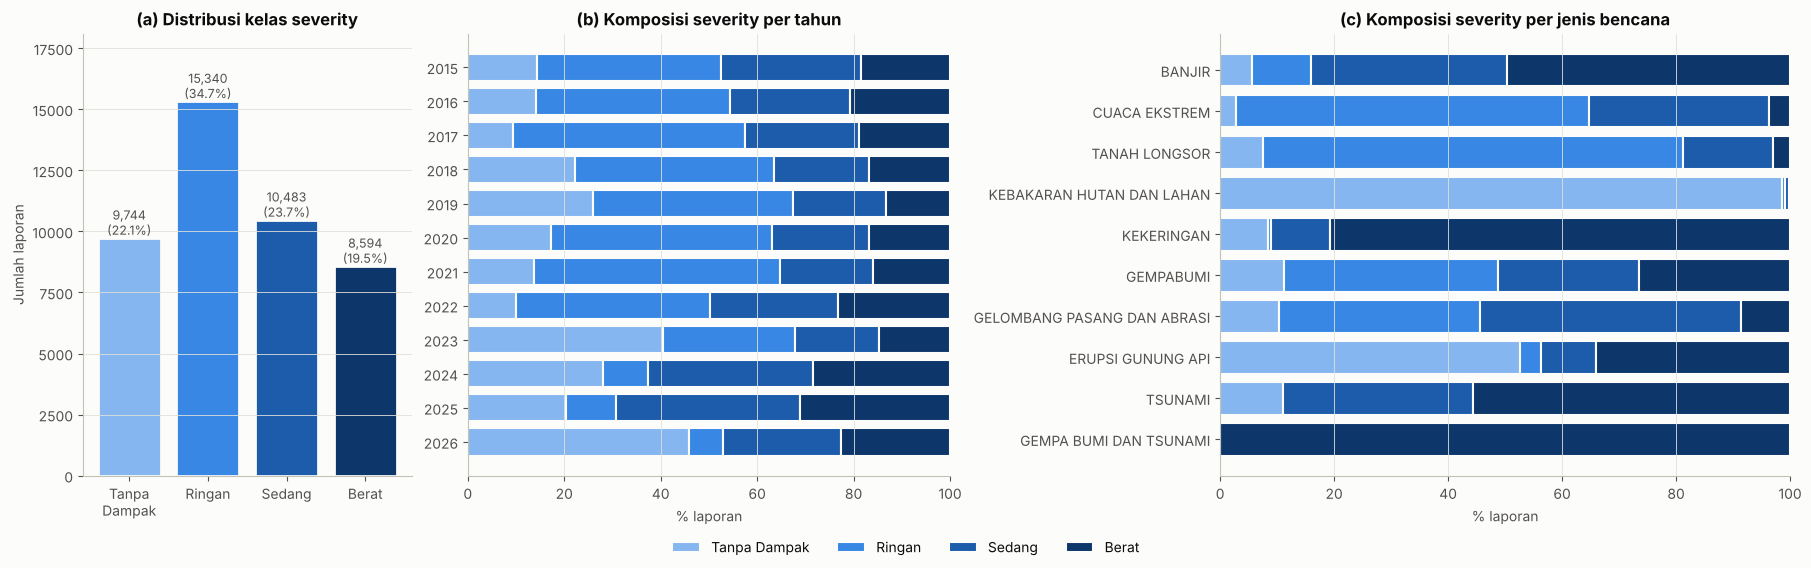

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={'width_ratios': [0.75, 1.1, 1.3]}, layout='constrained')

# (a) distribusi kelas
ax = axes[0]
bars = ax.bar([l.replace(' ', '\n') for l in SEV_LABELS], dist.values, color=SEV_COLORS, edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, labels=[f'{v:,}\n({v/len(df)*100:.1f}%)' for v in dist.values], fontsize=9, color=INK2)
ax.set(title='(a) Distribusi kelas severity', ylabel='Jumlah laporan'); ax.grid(axis='x', visible=False)
ax.set_ylim(0, dist.max() * 1.18)

def stacked_100(ax, ct, title):
    ct = ct.reindex(columns=SEV_LABELS, fill_value=0)
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    left = np.zeros(len(pct))
    for lab, col in zip(SEV_LABELS, SEV_COLORS):
        ax.barh(pct.index.astype(str), pct[lab], left=left, color=col, edgecolor=SURFACE, linewidth=1.5, label=lab)
        left += pct[lab].values
    ax.set(title=title, xlabel='% laporan', xlim=(0, 100)); ax.grid(axis='y', visible=False)
    ax.invert_yaxis()

# (b) per tahun → memperlihatkan perubahan pola pelaporan mulai 2024
stacked_100(axes[1], pd.crosstab(df.date.dt.year, df.severity), '(b) Komposisi severity per tahun')
# (c) per jenis bencana
order_k = df.kejadian.value_counts().index
stacked_100(axes[2], pd.crosstab(df.kejadian, df.severity).reindex(order_k), '(c) Komposisi severity per jenis bencana')
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4)
savefig(fig, 'clf_distribusi_severity.png'); plt.show()

**Catatan EDA penting untuk pemodelan:**
- Kelas relatif seimbang (rasio terbesar/terkecil < 2×), sehingga *accuracy* masih bermakna; tetap dilengkapi *balanced accuracy* & F1-macro.
- **Jenis bencana sangat menentukan severity** — mis. Karhutla hampir selalu "Tanpa Dampak" (tidak ada korban/rumah tercatat), Kekeringan dan Banjir dominan "Berat", Tanah Longsor & Cuaca Ekstrem dominan "Ringan/Sedang".
- **Mulai 2024 pola pelaporan berubah**: proporsi "Ringan" turun dari ±40% menjadi ±10% sedangkan "Sedang/Berat" naik (BNPB mulai rutin mengisi jumlah warga *menderita*). Ini bukan berarti bencana fisik tiba-tiba memburuk, melainkan **perubahan praktik pencatatan** — sehingga tahun & penanda era pelaporan perlu dimasukkan sebagai fitur.

## 3. Audit Kebocoran Data (*Data Leakage*)

Label severity adalah **fungsi deterministik** dari kolom korban/terdampak/rumah rusak. Jika kolom-kolom tersebut ikut menjadi fitur
(seperti skenario *post-event* di `bnpb_disaster_clf_ready.csv`), model hanya "menghafal" aturan ambang batas dan akurasinya mendekati 100%.
Hal yang sama berlaku untuk `kejadian_mean_severity`/`provinsi_mean_severity` di file tersebut karena di-*target-encode* dari seluruh data
(termasuk data uji). Cek cepat di bawah membuktikannya.

In [7]:
X_leak = df[IMPACT].values
y_all  = df['severity_code'].values
a_tr, a_te, b_tr, b_te = train_test_split(X_leak, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_SEED)
leak_acc = accuracy_score(b_te, DecisionTreeClassifier(random_state=RANDOM_SEED).fit(a_tr, b_tr).predict(a_te))
print(f'Accuracy Decision Tree dengan fitur dampak (post-event): {leak_acc:.4f}  ← kebocoran label, TIDAK dipakai')

Accuracy Decision Tree dengan fitur dampak (post-event): 0.9978  ← kebocoran label, TIDAK dipakai


➡️ **Keputusan:** semua fitur dampak (korban, pengungsi, rumah rusak, terendam, lahan, kerugian) **dikeluarkan**.
Model hanya memakai informasi yang **sudah tersedia saat laporan pertama masuk** (skenario *pre-event*).

## 4. Feature Engineering Pra-Kejadian

| Kelompok | Fitur | Keterangan |
|---|---|---|
| Jenis bencana | `kejadian` | one-hot (10 jenis) |
| Lokasi | `region`, `provinsi`, `lon`, `lat` | region pulau dari `id_prov`; koordinat titik (fallback rata-rata kab/kota → titik provinsi) |
| Waktu & musim | `month_sin`, `month_cos`, `musim_hujan`, `year`, `era_2024` | encoding siklikal bulan; musim hujan Nov–Mar; penanda era pelaporan baru |
| Riwayat wilayah | `kab_log_n`, `kab_sev_mean`, `kab_berat_rate`, `kab_days_since` | statistik laporan **sebelumnya** di kab/kota yang sama |
| Riwayat wilayah × jenis | `kabtype_log_n`, `kabtype_sev_mean`, `kabtype_berat_rate`, `kabtype_days_since` | statistik laporan **sebelumnya** dengan jenis bencana yang sama di kab/kota yang sama |

Fitur riwayat dihitung **hanya dari tanggal yang lebih awal** (bukan tanggal yang sama atau sesudahnya), lalu dihaluskan
(*Bayesian smoothing*, α = 5) agar wilayah dengan sedikit riwayat tidak menghasilkan rata-rata ekstrem. Dengan begitu, fitur ini
sah dipakai untuk prediksi — tidak ada informasi masa depan atau label laporan itu sendiri yang bocor.

In [8]:
def region_from_prov(p):
    p = int(p)
    if 11 <= p <= 21:   return 'Sumatera'
    if 31 <= p <= 36:   return 'Jawa'
    if p == 51:         return 'Bali'
    if p in (52, 53):   return 'Nusa Tenggara'
    if 61 <= p <= 65:   return 'Kalimantan'
    if 71 <= p <= 76:   return 'Sulawesi'
    if p in (81, 82):   return 'Maluku'
    return 'Papua'

df = df.sort_values('date').reset_index(drop=True)
df['region']      = df['id_prov'].apply(region_from_prov)
df['month']       = df.date.dt.month
df['year']        = df.date.dt.year
df['month_sin']   = np.sin(2 * np.pi * df.month / 12)
df['month_cos']   = np.cos(2 * np.pi * df.month / 12)
df['musim_hujan'] = df.month.isin([11, 12, 1, 2, 3]).astype(int)
df['era_2024']    = (df.year >= 2024).astype(int)

# Koordinat: titik kejadian → rata-rata kab/kota → titik provinsi → median
df['lon'] = pd.to_numeric(df.geometry_lon, errors='coerce')
df['lat'] = pd.to_numeric(df.geometry_lat, errors='coerce')
df.loc[~df.lon.between(94, 142), 'lon'] = np.nan
df.loc[~df.lat.between(-12, 7),  'lat'] = np.nan
for c, fallback in [('lon', 'lng_prov'), ('lat', 'lat_prov')]:
    df[c] = df[c].fillna(df.groupby('id_kab')[c].transform('mean'))
    df[c] = df[c].fillna(pd.to_numeric(df[fallback], errors='coerce'))
    df[c] = df[c].fillna(df[c].median())
print('Koordinat kosong setelah imputasi:', df[['lon', 'lat']].isna().sum().sum())

Koordinat kosong setelah imputasi: 0


In [9]:
def add_history_features(data, keys, prefix, alpha=5):
    # Statistik riwayat dari laporan dengan tanggal LEBIH AWAL pada grup `keys`
    d = data.copy()
    d['_berat'] = (d.severity_code == 3).astype(int)
    g = (d.groupby(keys + ['date'])
           .agg(_n=('severity_code', 'size'), _s=('severity_code', 'sum'), _b=('_berat', 'sum'))
           .reset_index().sort_values(keys + ['date']))
    for c in ['_n', '_s', '_b']:                                  # kumulatif SEBELUM tanggal ini
        g[c + '_past'] = g.groupby(keys)[c].cumsum() - g[c]
    g['_last'] = g.groupby(keys)['date'].shift(1)                 # tanggal laporan terakhir sebelumnya
    d = d.merge(g[keys + ['date', '_n_past', '_s_past', '_b_past', '_last']], on=keys + ['date'], how='left')

    # prior global dihitung dari periode awal (2015–2017) agar tidak memakai informasi masa depan
    early = d[d.year <= 2017]
    prior_sev, prior_berat = early.severity_code.mean(), (early.severity_code == 3).mean()
    d[f'{prefix}_log_n']      = np.log1p(d._n_past)
    d[f'{prefix}_sev_mean']   = (d._s_past + alpha * prior_sev)   / (d._n_past + alpha)
    d[f'{prefix}_berat_rate'] = (d._b_past + alpha * prior_berat) / (d._n_past + alpha)
    d[f'{prefix}_days_since'] = np.log1p((d.date - d._last).dt.days.fillna(3650))
    return d.drop(columns=['_berat', '_n_past', '_s_past', '_b_past', '_last'])

df = add_history_features(df, ['id_kab'], 'kab')
df = add_history_features(df, ['id_kab', 'kejadian'], 'kabtype')

CAT_FEATURES = ['kejadian', 'region', 'provinsi']
NUM_FEATURES = ['lon', 'lat', 'month_sin', 'month_cos', 'musim_hujan', 'year', 'era_2024',
                'kab_log_n', 'kab_sev_mean', 'kab_berat_rate', 'kab_days_since',
                'kabtype_log_n', 'kabtype_sev_mean', 'kabtype_berat_rate', 'kabtype_days_since']
FEATURES = CAT_FEATURES + NUM_FEATURES

X = df[FEATURES].copy()
y = df['severity_code'].values
print(f'Matriks fitur: {X.shape} | missing: {X.isna().sum().sum()}')
display(X.describe(include='all').T[['count', 'unique', 'mean', 'std', 'min', 'max']])

Matriks fitur: (44161, 18) | missing: 0


,count,unique,mean,std,min,max
kejadian,44161,10,NaN,NaN,NaN,NaN
region,44161,8,NaN,NaN,NaN,NaN
provinsi,44161,38,NaN,NaN,NaN,NaN
lon,44161.0,NaN,110.093689,7.242346,95.3056,140.809
lat,44161.0,NaN,-4.328147,3.87481,-10.726,5.83782
month_sin,44161.0,NaN,0.081325,0.725001,-1.0,1.0
month_cos,44161.0,NaN,0.129907,0.671495,-1.0,1.0
musim_hujan,44161.0,NaN,0.517561,0.499697,0.0,1.0
year,44161.0,NaN,2020.883019,2.962644,2015.0,2026.0
era_2024,44161.0,NaN,0.213356,0.409681,0.0,1.0


## 5. Pembagian Data & Preprocessing

- **Stratified split** 70% *train* / 10% *validation* / 20% *test*. Proporsi kelas sama di ketiga bagian.
- *Validation* dipakai untuk memantau kurva MSE selama pelatihan dan memilih iterasi/epoch terbaik (*early stopping*);
  *test* hanya dipakai **sekali** di akhir.
- Preprocessing (`OneHotEncoder` untuk kategorikal + `StandardScaler` untuk numerik) di-*fit* **hanya pada data train**.

In [10]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.125, stratify=y_tmp,
                                                  random_state=RANDOM_SEED)   # 0.125 × 80% = 10%

def make_preprocessor():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES),
        ('num', StandardScaler(), NUM_FEATURES)])

preprocessor = make_preprocessor().fit(X_train)
Z_train, Z_val, Z_test = (preprocessor.transform(x) for x in (X_train, X_val, X_test))
FEATURE_NAMES = preprocessor.get_feature_names_out()

split_tbl = pd.DataFrame({n: pd.Series(v).value_counts(normalize=True).sort_index().mul(100).round(1).values
                          for n, v in [('train', y_train), ('val', y_val), ('test', y_test)]}, index=SEV_LABELS)
split_tbl.loc['n baris'] = [len(y_train), len(y_val), len(y_test)]
print(f'Dimensi setelah encoding: {Z_train.shape[1]} fitur')
display(split_tbl)

Dimensi setelah encoding: 71 fitur


,train,val,test
Tanpa Dampak,22.1,22.1,22.1
Ringan,34.7,34.7,34.7
Sedang,23.7,23.7,23.7
Berat,19.5,19.5,19.5
n baris,30912.0,4416.0,8833.0


## 6. Teori: MSE & Gradient Descent pada Multi Perceptron

Mengacu pada materi **"Multi Perceptron Neural Networks"** (Ali Ridho Barakbah, PENS).

### 6.1 Learning Performance Analysis (rumus MSE)
Untuk setiap data masukan ke-*d* dengan *k* unit output (di sini *k* = 4 kelas severity, target di-*one-hot*):

$$SE_d = (Target_1 - C_1)^2 + (Target_2 - C_2)^2 + \dots + (Target_k - C_k)^2$$

$$SSE = \sum_{d=1}^{f} SE_d \qquad\qquad MSE = \frac{SSE}{f}$$

dengan *f* = jumlah total data masukan (*input sequence*), *Target* = vektor one-hot kelas sebenarnya, dan *C* = keluaran model
(probabilitas/aktivasi tiap kelas). Nilai MSE berada di rentang 0 (sempurna) hingga 2 (yakin penuh pada kelas yang salah).
Rumus yang sama diterapkan ke **semua model** memakai `predict_proba`, sehingga MSE dapat dibandingkan secara adil.

### 6.2 Backpropagation (aktivasi sigmoid)
- Sigmoid: $y = \dfrac{1}{1+e^{-x}}$, turunannya $y' = y(1-y)$
- Error output: $dC_j = C_j(1-C_j)(Target_j - C_j)$
- Error hidden: $dH_i = H_i(1-H_i)\sum_j wh_{(i,j)}\, dC_j$
- Update bobot: $dw_{(r,i)} = \mu \cdot I_r \cdot dH_i$ lalu $w_{(r,i)} = w_{(r,i)} + dw_{(r,i)}$ (bias: $I_0 = H_0 = 1$)

### 6.3 Gradient Descent
Setiap iterasi/epoch memperbarui bobot ke arah yang menurunkan error, sehingga **kurva MSE terhadap iterasi** menurun lalu melandai
(seperti slide *Gradient Descent*). Kurva pada data *validation* dipakai untuk melihat kapan model mulai *overfitting*.

In [11]:
def mse_pdf(y_true, C, k=4):
    # MSE sesuai slide Learning Performance Analysis: SE_d = Σ_k (Target_k − C_k)², MSE = SSE / f
    T    = np.eye(k)[np.asarray(y_true)]          # target one-hot
    SE_d = ((T - np.asarray(C)) ** 2).sum(axis=1)  # squared error tiap input sequence d
    SSE  = SE_d.sum()
    f    = len(SE_d)
    return SSE / f

# Contoh perhitungan manual 3 data (k = 4 kelas)
y_demo = np.array([3, 1, 0])
C_demo = np.array([[0.05, 0.10, 0.25, 0.60],    # benar (Berat) tapi tidak yakin
                   [0.10, 0.70, 0.15, 0.05],    # benar (Ringan)
                   [0.20, 0.50, 0.20, 0.10]])   # salah: target Tanpa Dampak, diprediksi Ringan
SE = ((np.eye(4)[y_demo] - C_demo) ** 2).sum(axis=1)
print('SE_d per data :', SE.round(4))
print(f'SSE = {SE.sum():.4f} | f = {len(SE)} | MSE = {SE.sum()/len(SE):.4f} | mse_pdf() = {mse_pdf(y_demo, C_demo):.4f}')

SE_d per data : [0.235 0.125 0.94 ]
SSE = 1.3000 | f = 3 | MSE = 0.4333 | mse_pdf() = 0.4333


## 7. Pelatihan Model & Pencatatan Kurva MSE

Enam model dibandingkan. Untuk setiap model dicatat MSE *train* dan *validation* di setiap iterasi pelatihan:

| # | Model | "Iterasi" pada kurva MSE | Pemilihan titik terbaik |
|---|---|---|---|
| 1 | **Logistic Regression** (softmax, solver SAGA = *stochastic gradient*) | epoch | epoch dengan MSE val terendah |
| 2 | **Decision Tree** | kedalaman pohon (model tidak iteratif → kurva kompleksitas) | `max_depth` dengan MSE val terendah |
| 3 | **Random Forest** | jumlah pohon (ensemble ditambah bertahap) | jumlah pohon dengan MSE val terendah |
| 4 | **Gradient Boosting** (HistGradientBoosting) | iterasi boosting = *gradient descent di ruang fungsi* | iterasi dengan MSE val terendah |
| 5 | **MLP scikit-learn** (ReLU + softmax, optimizer Adam) | epoch | epoch dengan MSE val terendah |
| 6 | **MLP Backpropagation manual** (sigmoid, persis rumus materi) | epoch | epoch dengan MSE val terendah |

In [12]:
results = {}   # menampung model final, riwayat MSE, dan info pelatihan

def record(name, model, history, iter_label, best_iter, train_time, params):
    results[name] = dict(model=model, history=pd.DataFrame(history, columns=['iter', 'mse_train', 'mse_val']),
                         iter_label=iter_label, best_iter=best_iter, train_time=train_time, params=params)
    h = results[name]['history']; b = h.loc[h.mse_val.idxmin()]
    print(f'{name:24s} | iterasi terbaik ({iter_label}) = {best_iter:>4} | MSE train = {b.mse_train:.4f} '
          f'| MSE val = {b.mse_val:.4f} | waktu = {train_time:.1f} s')

def evaluate_curve_point(model, it):
    return (it, mse_pdf(y_train, model.predict_proba(Z_train)), mse_pdf(y_val, model.predict_proba(Z_val)))

### 7.1 Logistic Regression (Softmax) — Stochastic Gradient (SAGA)

In [13]:
t0 = time.time()
logreg = LogisticRegression(solver='saga', C=1.0, max_iter=1, tol=1e-12, warm_start=True, random_state=RANDOM_SEED)
# epoch 0 = bobot awal nol → probabilitas seragam 0.25 untuk setiap kelas
hist = [(0, mse_pdf(y_train, np.full((len(y_train), 4), 0.25)), mse_pdf(y_val, np.full((len(y_val), 4), 0.25)))]
best = (np.inf, None, 0)
for ep in range(1, 31):                      # 1 panggilan fit = 1 epoch (warm_start melanjutkan bobot)
    logreg.fit(Z_train, y_train)
    hist.append(evaluate_curve_point(logreg, ep))
    if hist[-1][2] < best[0]:
        best = (hist[-1][2], copy.deepcopy(logreg), ep)
record('Logistic Regression', best[1], hist, 'epoch', best[2], time.time() - t0, {'solver': 'saga', 'C': 1.0, 'epochs': best[2]})

Logistic Regression      | iterasi terbaik (epoch) =    2 | MSE train = 0.4119 | MSE val = 0.4079 | waktu = 2.3 s


### 7.2 Decision Tree — kurva kompleksitas (max_depth)

In [14]:
t0 = time.time()
hist, best = [], (np.inf, None, 0)
for depth in range(1, 21):
    dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=RANDOM_SEED).fit(Z_train, y_train)
    hist.append(evaluate_curve_point(dt, depth))
    if hist[-1][2] < best[0]:
        best = (hist[-1][2], dt, depth)
record('Decision Tree', best[1], hist, 'max_depth', best[2], time.time() - t0, {'max_depth': best[2], 'min_samples_leaf': 20})

Decision Tree            | iterasi terbaik (max_depth) =    9 | MSE train = 0.3926 | MSE val = 0.4064 | waktu = 5.5 s


### 7.3 Random Forest — MSE vs jumlah pohon

In [15]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=0, min_samples_leaf=3, max_features='sqrt', warm_start=True,
                            n_jobs=-1, random_state=RANDOM_SEED)
hist = []
for n_trees in range(10, 301, 10):
    rf.set_params(n_estimators=n_trees).fit(Z_train, y_train)     # menambah 10 pohon tiap langkah
    hist.append(evaluate_curve_point(rf, n_trees))
best_n = int(pd.DataFrame(hist, columns=['iter', 'tr', 'va']).set_index('iter').va.idxmin())
rf_best = RandomForestClassifier(n_estimators=best_n, min_samples_leaf=3, max_features='sqrt',
                                 n_jobs=-1, random_state=RANDOM_SEED).fit(Z_train, y_train)
record('Random Forest', rf_best, hist, 'jumlah pohon', best_n, time.time() - t0,
       {'n_estimators': best_n, 'min_samples_leaf': 3, 'max_features': 'sqrt'})

Random Forest            | iterasi terbaik (jumlah pohon) =  300 | MSE train = 0.2278 | MSE val = 0.3962 | waktu = 29.7 s


### 7.4 Gradient Boosting — MSE per iterasi boosting

In [16]:
t0 = time.time()
GB_PARAMS = dict(learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, early_stopping=False,
                 random_state=RANDOM_SEED)
gb = HistGradientBoostingClassifier(max_iter=500, **GB_PARAMS).fit(Z_train, y_train)
hist = [(i + 1, mse_pdf(y_train, p_tr), mse_pdf(y_val, p_va))
        for i, (p_tr, p_va) in enumerate(zip(gb.staged_predict_proba(Z_train), gb.staged_predict_proba(Z_val)))]
best_it = int(pd.DataFrame(hist, columns=['iter', 'tr', 'va']).set_index('iter').va.idxmin())
gb_best = HistGradientBoostingClassifier(max_iter=best_it, **GB_PARAMS).fit(Z_train, y_train)
record('Gradient Boosting', gb_best, hist, 'iterasi boosting', best_it, time.time() - t0,
       {'max_iter': best_it, **{k: v for k, v in GB_PARAMS.items() if k != 'random_state'}})

Gradient Boosting        | iterasi terbaik (iterasi boosting) =   64 | MSE train = 0.3701 | MSE val = 0.3950 | waktu = 28.7 s


### 7.5 MLP scikit-learn (Adam)

In [17]:
t0 = time.time()
MLP_PARAMS = dict(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=1e-4,
                  batch_size=256, learning_rate_init=1e-3, random_state=RANDOM_SEED)
mlp = MLPClassifier(**MLP_PARAMS)
classes = np.unique(y_train)
hist, best = [], (np.inf, None, 0)
for ep in range(1, 81):                     # 1 partial_fit = 1 epoch
    mlp.partial_fit(Z_train, y_train, classes=classes)
    hist.append(evaluate_curve_point(mlp, ep))
    if hist[-1][2] < best[0]:
        best = (hist[-1][2], copy.deepcopy(mlp), ep)
record('MLP (scikit-learn)', best[1], hist, 'epoch', best[2], time.time() - t0, {**MLP_PARAMS, 'epochs': best[2]})

MLP (scikit-learn)       | iterasi terbaik (epoch) =    9 | MSE train = 0.3905 | MSE val = 0.3948 | waktu = 14.0 s


### 7.6 MLP Backpropagation Manual (implementasi langsung dari materi)

Implementasi NumPy berikut mengikuti slide *Feed Forward*, *Backward Error*, *Weight Update*, *k Output Units* dan *L Hidden Layers*:
aktivasi **sigmoid** di semua layer, bias berupa input bernilai 1, error output $dC_j = C_j(1-C_j)(T_j-C_j)$, error hidden
$dH_i = H_i(1-H_i)\sum_j w_{(i,j)}dC_j$, dan update $w = w + \mu \cdot \text{input} \cdot \text{delta}$.
Agar cepat untuk ±31 ribu data, update dilakukan per *mini-batch* (rata-rata `dw` dalam satu batch; jika `batch_size=1`
hasilnya identik dengan update per data seperti di slide).

In [18]:
class BackpropMLP(ClassifierMixin, BaseEstimator):
    # Multi Perceptron + Backpropagation sesuai materi (sigmoid, k output units, L hidden layers)

    def __init__(self, hidden_layers=(32,), mu=0.5, epochs=100, batch_size=64, init_range=0.5, random_state=42):
        self.hidden_layers, self.mu, self.epochs = hidden_layers, mu, epochs
        self.batch_size, self.init_range, self.random_state = batch_size, init_range, random_state

    @staticmethod
    def _sigmoid(x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))

    @staticmethod
    def _bias(A):                                   # tambahkan input bias I0 = 1 / H0 = 1
        return np.hstack([np.ones((A.shape[0], 1)), A])

    def _forward(self, X):                          # Feed Forward: Σ lalu ∫ (sigmoid) di setiap layer
        acts = [X]
        for W in self.weights_:
            acts.append(self._sigmoid(self._bias(acts[-1]) @ W))
        return acts                                 # [I, H1, ..., HL, C]

    def fit(self, X, y, X_val=None, y_val=None):
        X, y = np.asarray(X, float), np.asarray(y)
        self.classes_ = np.unique(y)
        T = (y[:, None] == self.classes_[None, :]).astype(float)      # Target one-hot (k output units)
        rng = np.random.default_rng(self.random_state)
        sizes = [X.shape[1], *self.hidden_layers, len(self.classes_)]
        # baris 0 tiap matriks = bobot bias (wi_(0,i), wh_(0,j))
        self.weights_ = [rng.uniform(-self.init_range, self.init_range, (sizes[i] + 1, sizes[i + 1]))
                         for i in range(len(sizes) - 1)]
        self.history_, best_val, best_w = [], np.inf, None
        y_idx = np.searchsorted(self.classes_, y)
        if X_val is not None:                                               # epoch 0 = bobot acak awal
            self.history_.append((0, mse_pdf(y_idx, self.predict_proba(X)),
                                  mse_pdf(np.searchsorted(self.classes_, y_val), self.predict_proba(X_val))))
        for ep in range(1, self.epochs + 1):
            idx = rng.permutation(len(X))                                   # acak urutan data tiap epoch
            for s in range(0, len(X), self.batch_size):
                b = idx[s:s + self.batch_size]
                acts = self._forward(X[b])
                C = acts[-1]
                delta = C * (1 - C) * (T[b] - C)                           # dC_j = C_j(1−C_j)(Target_j − C_j)
                for L in range(len(self.weights_) - 1, -1, -1):
                    inp = self._bias(acts[L])
                    dW = self.mu * inp.T @ delta / len(b)                   # dw = μ · input · delta
                    if L > 0:
                        H = acts[L]
                        delta = H * (1 - H) * (delta @ self.weights_[L][1:].T)   # dH_i = H_i(1−H_i) Σ_j w_ij·dC_j
                    self.weights_[L] += dW                                  # w = w + dw
            if X_val is None:                                               # tanpa validation: tidak perlu mencatat kurva
                continue
            mse_tr = mse_pdf(y_idx, self.predict_proba(X))
            mse_va = mse_pdf(np.searchsorted(self.classes_, y_val), self.predict_proba(X_val))
            self.history_.append((ep, mse_tr, mse_va))
            if X_val is not None and mse_va < best_val:                     # simpan bobot terbaik (early stopping)
                best_val, best_w, self.best_epoch_ = mse_va, [w.copy() for w in self.weights_], ep
        if best_w is not None:
            self.weights_ = best_w
        return self

    def predict_proba(self, X):
        return self._forward(np.asarray(X, float))[-1]      # keluaran C_k (sigmoid) apa adanya, sesuai materi

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [19]:
t0 = time.time()
# μ = 0.2 dipilih karena kurva lebih stabil dibanding μ = 0.5 (MSE val tidak naik-turun tajam antar-epoch)
BP_PARAMS = dict(hidden_layers=(32,), mu=0.2, epochs=150, batch_size=64, init_range=0.5, random_state=RANDOM_SEED)
bp = BackpropMLP(**BP_PARAMS).fit(Z_train, y_train, Z_val, y_val)
record('MLP Backprop (manual)', bp, bp.history_, 'epoch', bp.best_epoch_, time.time() - t0,
       {**BP_PARAMS, 'epochs': bp.best_epoch_})

MLP Backprop (manual)    | iterasi terbaik (epoch) =  143 | MSE train = 0.3979 | MSE val = 0.3973 | waktu = 13.8 s


## 8. Kurva Gradient Descent MSE

Garis **tegas = validation**, garis **putus-putus = train**; titik bulat menandai iterasi terbaik (MSE val terendah).

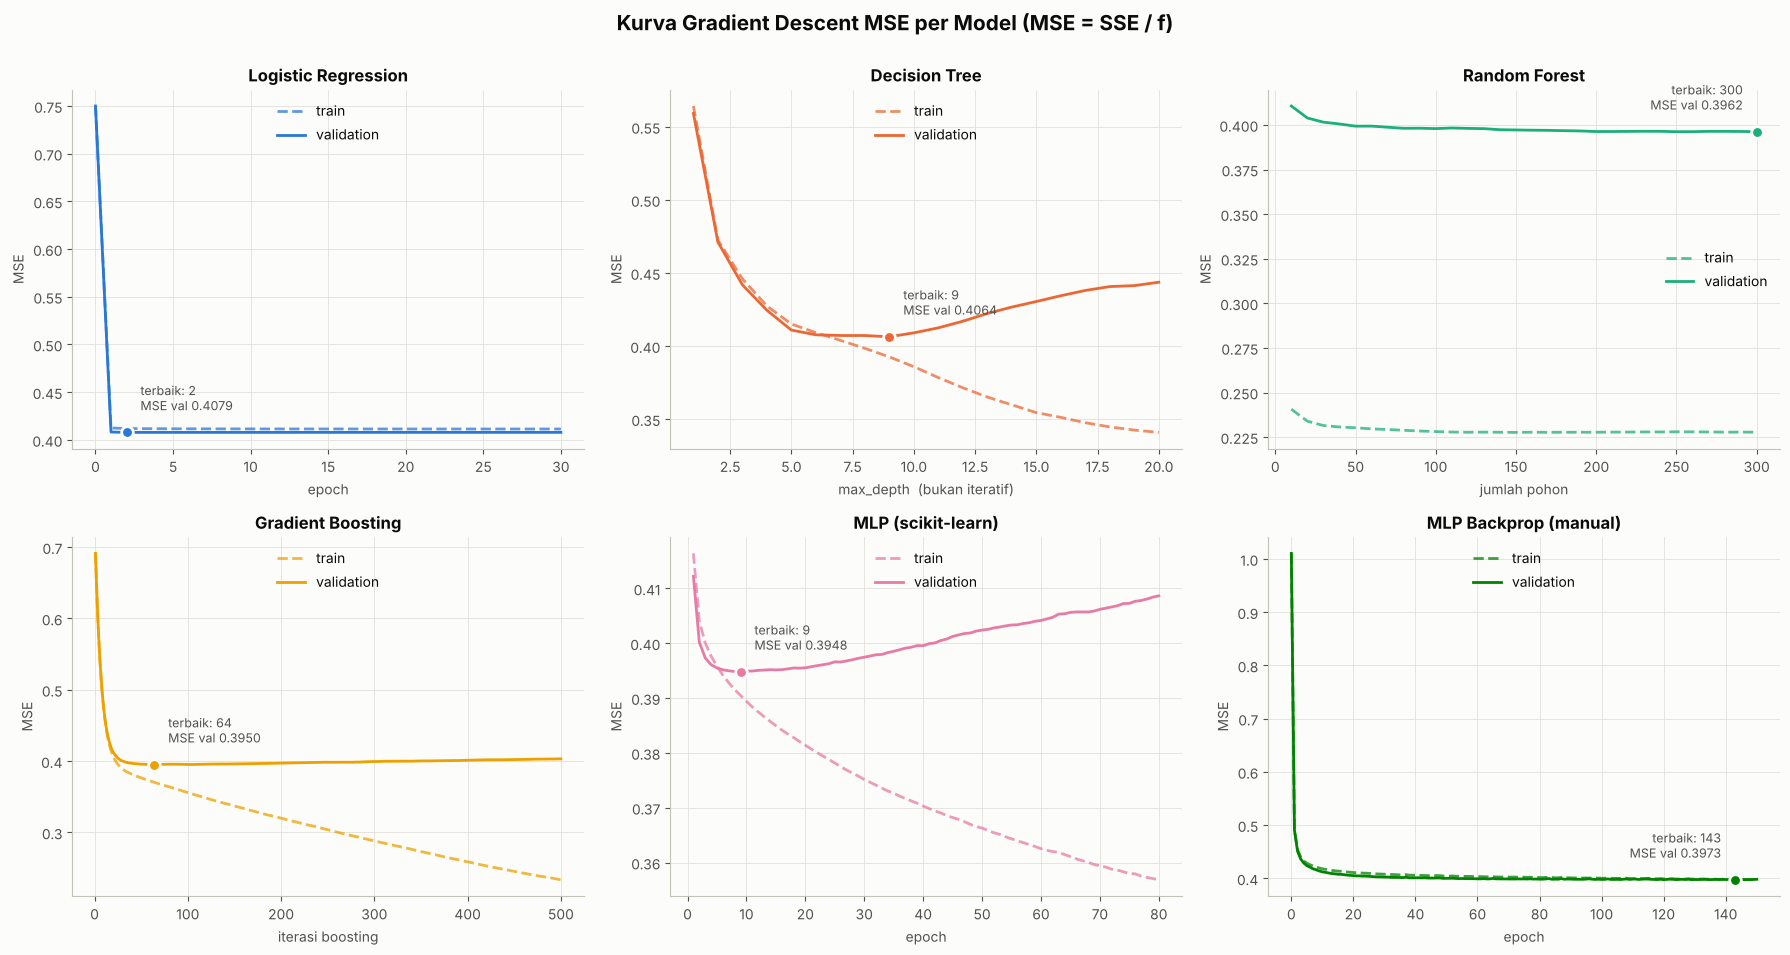

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9.5))
for ax, name in zip(axes.ravel(), MODEL_ORDER):
    r, col = results[name], MODEL_COLORS[name]
    h = r['history']
    ax.plot(h.iter, h.mse_train, ls='--', color=col, alpha=0.75, label='train')
    ax.plot(h.iter, h.mse_val, color=col, label='validation')
    b = h.loc[h.mse_val.idxmin()]
    ax.scatter([b.iter], [b.mse_val], s=70, color=col, edgecolor=SURFACE, linewidth=2, zorder=5)
    near_right = b.iter > h.iter.min() + 0.7 * (h.iter.max() - h.iter.min())
    ax.annotate(f'terbaik: {int(b.iter)}\nMSE val {b.mse_val:.4f}', (b.iter, b.mse_val),
                textcoords='offset points', xytext=(-10, 16) if near_right else (10, 16),
                ha='right' if near_right else 'left', fontsize=9, color=INK2)
    note = '  (bukan iteratif)' if name == 'Decision Tree' else ''
    ax.set(title=name, xlabel=r['iter_label'] + note, ylabel='MSE')
    ax.legend(loc='center right' if name == 'Random Forest' else 'upper center')
fig.suptitle('Kurva Gradient Descent MSE per Model (MSE = SSE / f)', fontsize=15, fontweight='bold', y=1.0)
plt.tight_layout(); savefig(fig, 'clf_gradient_descent_mse.png'); plt.show()

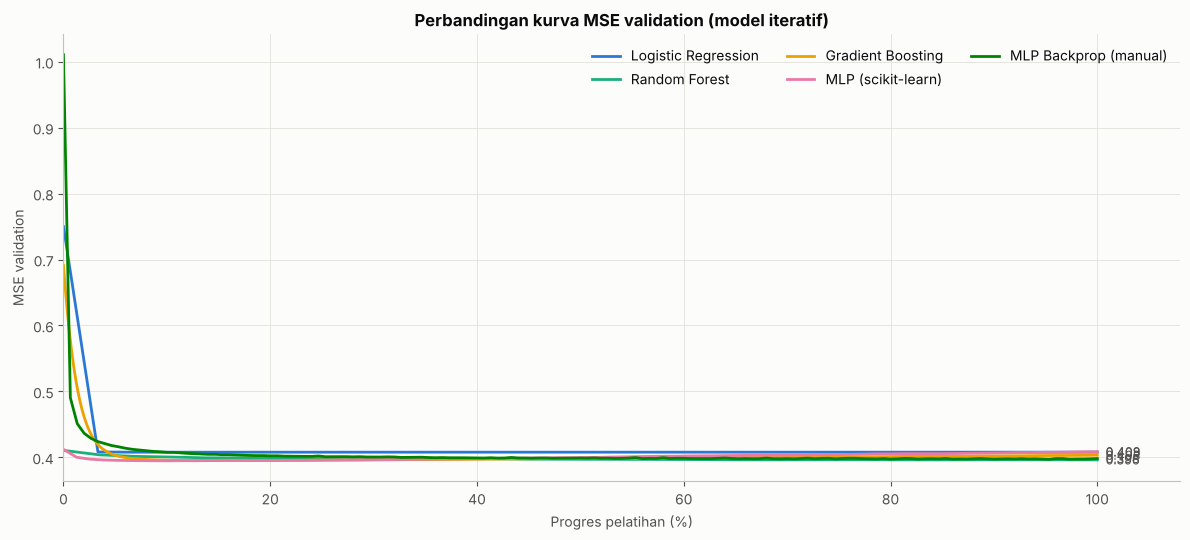

In [21]:
# Kurva validation semua model iteratif pada sumbu progres pelatihan ternormalisasi (0–100%)
fig, ax = plt.subplots(figsize=(12, 5.5))
for name in MODEL_ORDER:
    if name == 'Decision Tree':
        continue
    h = results[name]['history']
    prog = (h.iter - h.iter.min()) / (h.iter.max() - h.iter.min()) * 100
    ax.plot(prog, h.mse_val, color=MODEL_COLORS[name], label=name)
    ax.annotate(f'{h.mse_val.iloc[-1]:.3f}', (100, h.mse_val.iloc[-1]), textcoords='offset points',
                xytext=(6, 0), va='center', fontsize=9, color=INK2)
ax.set(title='Perbandingan kurva MSE validation (model iteratif)', xlabel='Progres pelatihan (%)',
       ylabel='MSE validation', xlim=(0, 108))
ax.legend(ncol=3, loc='upper right')
plt.tight_layout(); savefig(fig, 'clf_mse_validation_overlay.png'); plt.show()

## 9. Evaluasi Data Uji: Classification Report & Confusion Matrix

In [22]:
rows, preds, probas = [], {}, {}
for name in MODEL_ORDER:
    r = results[name]; m = r['model']
    t0 = time.time(); P = m.predict_proba(Z_test); pred_time = time.time() - t0
    yp = P.argmax(axis=1)
    preds[name], probas[name] = yp, P
    h = r['history']; b = h.loc[h.mse_val.idxmin()]
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, yp),
        'balanced_accuracy': balanced_accuracy_score(y_test, yp),   # rata-rata diagonal CM ternormalisasi
        'f1_macro': f1_score(y_test, yp, average='macro'),
        'f1_weighted': f1_score(y_test, yp, average='weighted'),
        'recall_berat': recall_score(y_test, yp, labels=[3], average='macro'),
        'mse_train': b.mse_train, 'mse_val': b.mse_val,
        'mse_test': mse_pdf(y_test, P),
        'iterasi_terbaik': f"{int(b.iter)} ({r['iter_label']})",
        'waktu_latih_s': r['train_time'],
    })
summary = pd.DataFrame(rows).set_index('model')

for name in MODEL_ORDER:
    display(Markdown(f'**{name}** — accuracy {summary.loc[name, "accuracy"]:.4f} | MSE test {summary.loc[name, "mse_test"]:.4f}'))
    print(classification_report(y_test, preds[name], target_names=SEV_LABELS, digits=4))

**Logistic Regression** — accuracy 0.6865 | MSE test 0.4123

              precision    recall  f1-score   support

Tanpa Dampak     0.9676    0.7978    0.8746      1949
      Ringan     0.7026    0.8439    0.7668      3068
      Sedang     0.4821    0.3209    0.3853      2097
       Berat     0.5814    0.7254    0.6454      1719

    accuracy                         0.6865      8833
   macro avg     0.6834    0.6720    0.6680      8833
weighted avg     0.6851    0.6865    0.6764      8833



**Decision Tree** — accuracy 0.6879 | MSE test 0.4213

              precision    recall  f1-score   support

Tanpa Dampak     0.9657    0.7948    0.8719      1949
      Ringan     0.7095    0.8224    0.7618      3068
      Sedang     0.4764    0.3615    0.4111      2097
       Berat     0.5985    0.7248    0.6556      1719

    accuracy                         0.6879      8833
   macro avg     0.6875    0.6759    0.6751      8833
weighted avg     0.6891    0.6879    0.6822      8833



**Random Forest** — accuracy 0.7013 | MSE test 0.4018

...

              precision    recall  f1-score   support

Tanpa Dampak     0.9726    0.8019    0.8791      1949
      Ringan     0.7186    0.8341    0.7721      3068
      Sedang     0.5020    0.3662    0.4235      2097
       Berat     0.5981    0.7429    0.6627      1719

    accuracy                         0.6982      8833
   macro avg     0.6978    0.6863    0.6843      8833
weighted avg     0.6998    0.6982    0.6916      8833



**MLP (scikit-learn)** — accuracy 0.6983 | MSE test 0.4024

              precision    recall  f1-score   support

Tanpa Dampak     0.9707    0.7984    0.8761      1949
      Ringan     0.7204    0.8357    0.7738      3068
      Sedang     0.5019    0.3686    0.4251      2097
       Berat     0.5983    0.7417    0.6623      1719

    accuracy                         0.6983      8833
   macro avg     0.6978    0.6861    0.6843      8833
weighted avg     0.7000    0.6983    0.6919      8833



**MLP Backprop (manual)** — accuracy 0.6987 | MSE test 0.4042

              precision    recall  f1-score   support

Tanpa Dampak     0.9731    0.7984    0.8771      1949
      Ringan     0.7189    0.8377    0.7737      3068
      Sedang     0.5082    0.3534    0.4169      2097
       Berat     0.5929    0.7592    0.6658      1719

    accuracy                         0.6987      8833
   macro avg     0.6983    0.6871    0.6834      8833
weighted avg     0.7005    0.6987    0.6908      8833



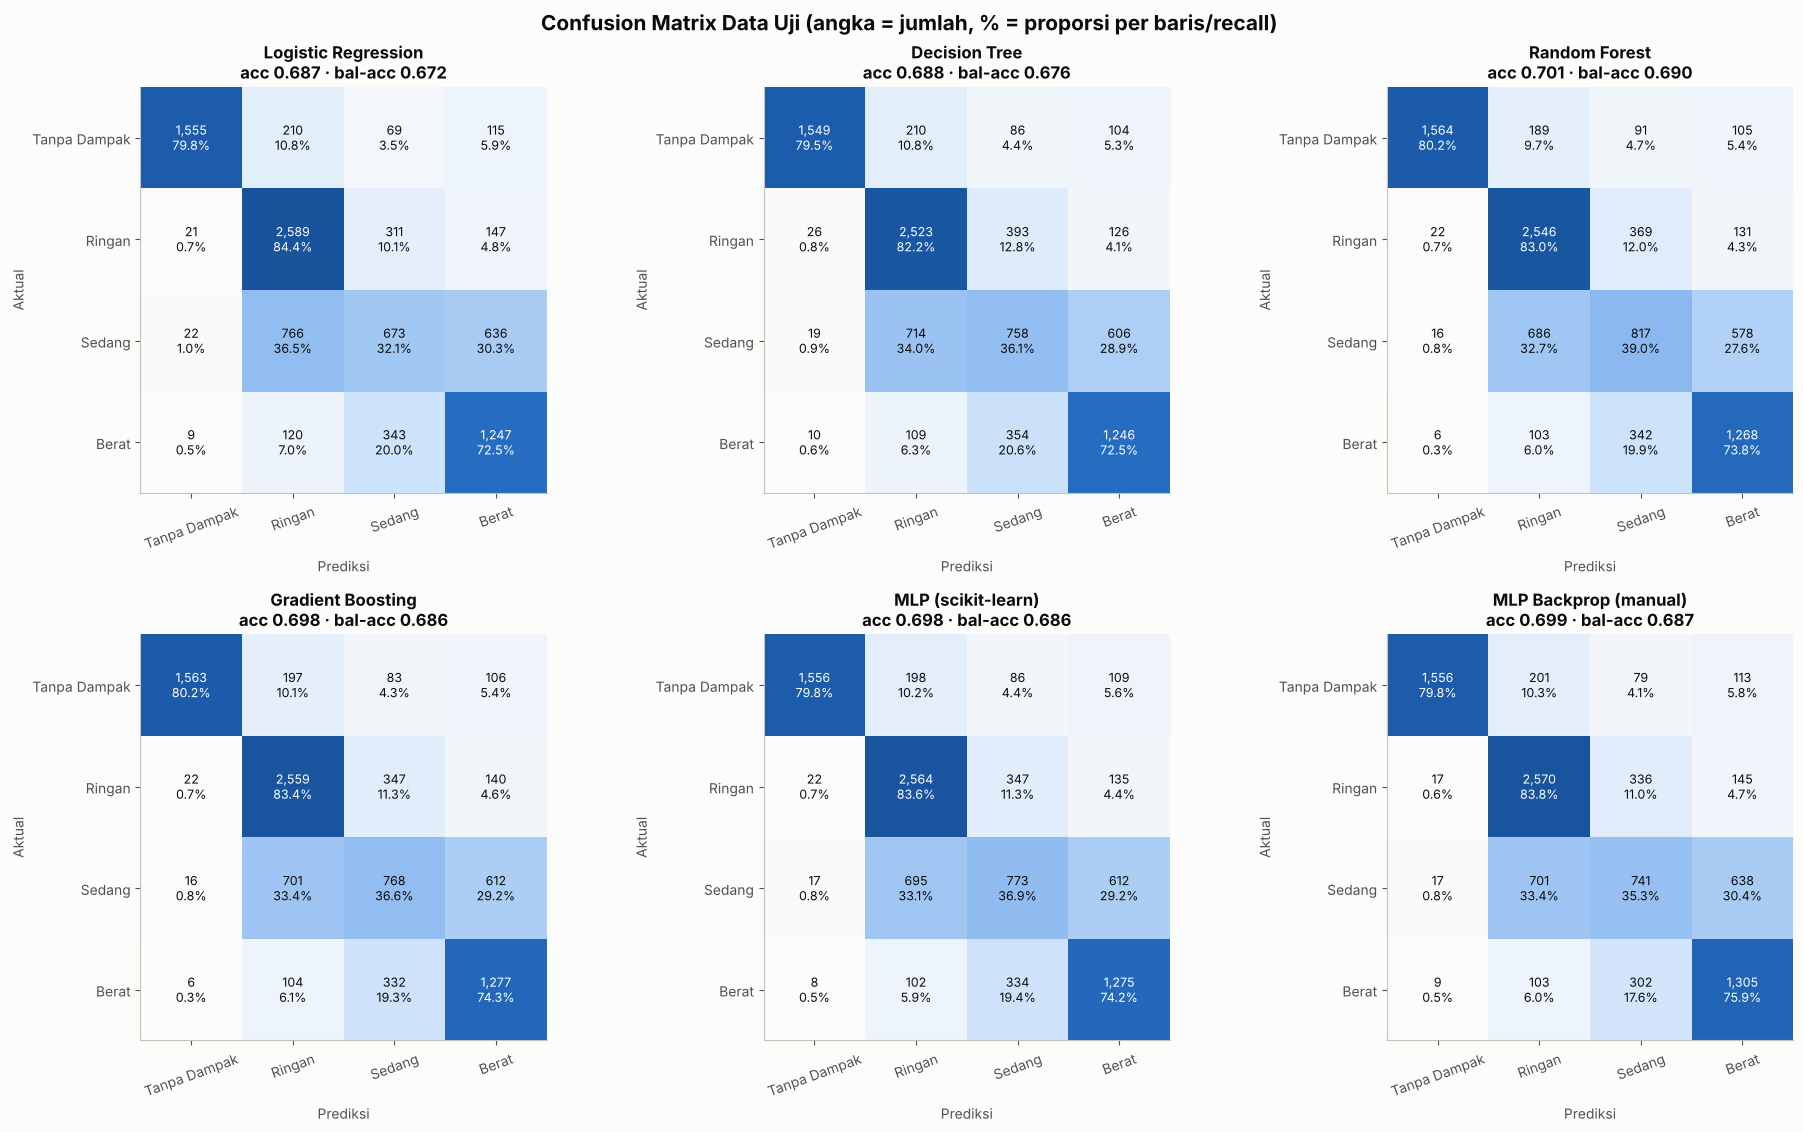

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
for ax, name in zip(axes.ravel(), MODEL_ORDER):
    cm = confusion_matrix(y_test, preds[name], labels=range(4))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap=CM_CMAP, vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{cm[i, j]:,}\n{cmn[i, j]*100:.1f}%', ha='center', va='center', fontsize=9,
                    color='#ffffff' if cmn[i, j] > 0.5 else INK)
    ax.set_xticks(range(4), SEV_LABELS, rotation=20); ax.set_yticks(range(4), SEV_LABELS)
    ax.set(xlabel='Prediksi', ylabel='Aktual', title=f"{name}\nacc {summary.loc[name, 'accuracy']:.3f} · "
                                                      f"bal-acc {summary.loc[name, 'balanced_accuracy']:.3f}")
    ax.grid(False)
fig.suptitle('Confusion Matrix Data Uji (angka = jumlah, % = proporsi per baris/recall)', fontsize=15, fontweight='bold')
plt.tight_layout(); savefig(fig, 'clf_confusion_matrices.png'); plt.show()

## 10. Perbandingan & Pemilihan Model Terbaik

Setiap model diberi peringkat pada tiga kriteria (accuracy ↑, balanced accuracy dari confusion matrix ↑, MSE test ↓).
Model terbaik = rata-rata peringkat terkecil; jika seri, dipilih MSE test terendah.

In [24]:
summary['rank_accuracy']  = summary['accuracy'].rank(ascending=False, method='min')
summary['rank_conf_mat']  = summary['balanced_accuracy'].rank(ascending=False, method='min')
summary['rank_mse']       = summary['mse_test'].rank(ascending=True, method='min')
summary['skor_peringkat'] = summary[['rank_accuracy', 'rank_conf_mat', 'rank_mse']].mean(axis=1)
summary = summary.sort_values(['skor_peringkat', 'mse_test'])
BEST = summary.index[0]

fmt = {c: '{:.4f}' for c in ['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted', 'recall_berat',
                              'mse_train', 'mse_val', 'mse_test']}
fmt.update({'waktu_latih_s': '{:.1f}', 'skor_peringkat': '{:.2f}'})
display(summary.style.format(fmt)
        .highlight_max(subset=['accuracy', 'balanced_accuracy', 'f1_macro', 'recall_berat'], color='#cde2fb')
        .highlight_min(subset=['mse_test'], color='#cde2fb'))
display(Markdown(f'### 🏆 Model terbaik: **{BEST}**  '
                 f'(accuracy {summary.loc[BEST, "accuracy"]:.4f}, balanced accuracy {summary.loc[BEST, "balanced_accuracy"]:.4f}, '
                 f'MSE test {summary.loc[BEST, "mse_test"]:.4f})'))

,accuracy,balanced_accuracy,f1_macro,f1_weighted,recall_berat,mse_train,mse_val,mse_test,iterasi_terbaik,waktu_latih_s,rank_accuracy,rank_conf_mat,rank_mse,skor_peringkat
model,,,,,,,,,,,,,,
Random Forest,0.7013,0.6899,0.6897,0.6966,0.7376,0.2278,0.3962,0.4018,300 (jumlah pohon),29.7,1.000000,1.000000,2.000000,1.33
Gradient Boosting,0.6982,0.6863,0.6843,0.6916,0.7429,0.3701,0.3950,0.4009,64 (iterasi boosting),28.7,4.000000,3.000000,1.000000,2.67
MLP Backprop (manual),0.6987,0.6871,0.6834,0.6908,0.7592,0.3979,0.3973,0.4042,143 (epoch),13.8,2.000000,2.000000,4.000000,2.67
MLP (scikit-learn),0.6983,0.6861,0.6843,0.6919,0.7417,0.3905,0.3948,0.4024,9 (epoch),14.0,3.000000,4.000000,3.000000,3.33
Decision Tree,0.6879,0.6759,0.6751,0.6822,0.7248,0.3926,0.4064,0.4213,9 (max_depth),5.5,5.000000,5.000000,6.000000,5.33
Logistic Regression,0.6865,0.6720,0.6680,0.6764,0.7254,0.4119,0.4079,0.4123,2 (epoch),2.3,6.000000,6.000000,5.000000,5.67


### 🏆 Model terbaik: **Random Forest**  (accuracy 0.7013, balanced accuracy 0.6899, MSE test 0.4018)

,accuracy,mse_test
Baseline: kelas mayoritas,0.3473,1.3053
Baseline: jenis bencana saja,0.6647,0.4472


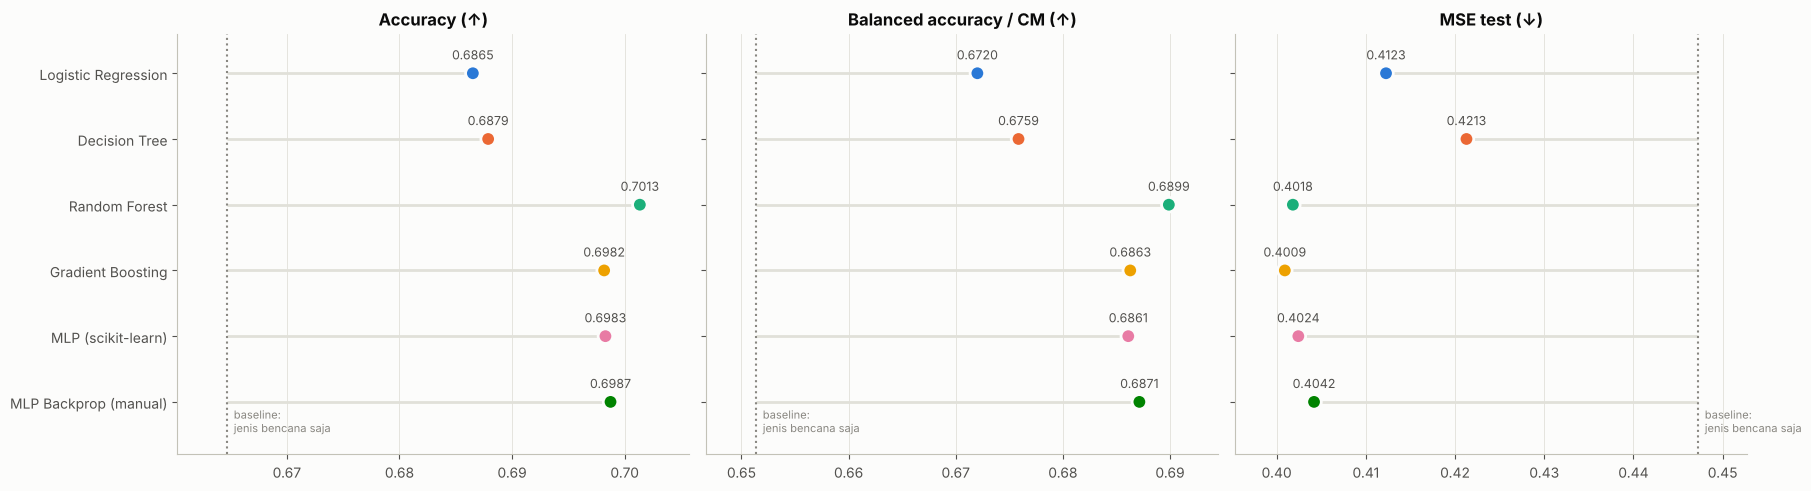

In [25]:
# Baseline sebagai pembanding: tebak kelas mayoritas, dan model yang hanya tahu jenis bencana
prior = np.bincount(y_train, minlength=4) / len(y_train)
base_major = dict(accuracy=accuracy_score(y_test, np.full_like(y_test, prior.argmax())),
                  mse_test=mse_pdf(y_test, np.tile(np.eye(4)[prior.argmax()], (len(y_test), 1))))
pk = ColumnTransformer([('k', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['kejadian'])])
lr_k = LogisticRegression(max_iter=1000).fit(pk.fit_transform(X_train), y_train)
P_k = lr_k.predict_proba(pk.transform(X_test))
base_type = dict(accuracy=accuracy_score(y_test, P_k.argmax(1)), mse_test=mse_pdf(y_test, P_k))
baselines = pd.DataFrame({'Baseline: kelas mayoritas': base_major, 'Baseline: jenis bencana saja': base_type}).T
display(baselines.style.format('{:.4f}'))

# Dot plot (bukan batang) karena selisih antarmodel kecil dan sumbu tidak dimulai dari nol
base_bal = balanced_accuracy_score(y_test, P_k.argmax(1))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), layout='constrained')
for ax, (col, title, base_v) in zip(axes, [('accuracy', 'Accuracy (↑)', base_type['accuracy']),
                                           ('balanced_accuracy', 'Balanced accuracy / CM (↑)', base_bal),
                                           ('mse_test', 'MSE test (↓)', base_type['mse_test'])]):
    s = summary[col].reindex(MODEL_ORDER)
    yy = np.arange(len(MODEL_ORDER))
    ax.hlines(yy, base_v, s.values, color=GRID, lw=2, zorder=1)
    ax.scatter(s.values, yy, s=110, color=[MODEL_COLORS[m] for m in MODEL_ORDER], edgecolor=SURFACE, linewidth=2, zorder=3)
    for i, v in enumerate(s.values):
        ax.annotate(f'{v:.4f}', (v, i), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9, color=INK2)
    ax.axvline(base_v, color=MUTED, ls=':', lw=1.5)
    ax.annotate('baseline:\njenis bencana saja', (base_v, len(MODEL_ORDER) - 0.5), textcoords='offset points',
                xytext=(5, 0), fontsize=8, color=MUTED, va='bottom')
    lo, hi = min(s.min(), base_v), max(s.max(), base_v); pad = (hi - lo) * 0.12
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(len(MODEL_ORDER) - 0.2, -0.6)
    ax.set_yticks(yy, MODEL_ORDER if ax is axes[0] else [''] * len(MODEL_ORDER))
    ax.grid(axis='y', visible=False); ax.set(title=title)
savefig(fig, 'clf_perbandingan_model.png'); plt.show()

## 11. Validasi Silang Stratified 5-Fold (Uji Kestabilan)

Selisih antarmodel pada satu data uji bisa saja kebetulan. Validasi silang 5-fold dengan hyperparameter terpilih
(iterasi terbaik di bagian 7) memeriksa apakah urutan model konsisten.

In [26]:
def make_model(name):
    p = results[name]['params']
    if name == 'Logistic Regression':
        return LogisticRegression(solver='saga', C=p['C'], max_iter=p['epochs'], tol=1e-12, random_state=RANDOM_SEED)
    if name == 'Decision Tree':
        return DecisionTreeClassifier(max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'], random_state=RANDOM_SEED)
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=p['n_estimators'], min_samples_leaf=p['min_samples_leaf'],
                                      max_features=p['max_features'], n_jobs=-1, random_state=RANDOM_SEED)
    if name == 'Gradient Boosting':
        return HistGradientBoostingClassifier(**{**GB_PARAMS, 'max_iter': p['max_iter']})
    if name == 'MLP (scikit-learn)':
        return MLPClassifier(**{**MLP_PARAMS, 'max_iter': p['epochs']})
    if name == 'MLP Backprop (manual)':
        return BackpropMLP(**{**BP_PARAMS, 'epochs': p['epochs']})

if RUN_CV:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    cv_rows = []
    t0 = time.time()
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        pre_f = make_preprocessor().fit(X.iloc[tr])
        Ztr_f, Zte_f = pre_f.transform(X.iloc[tr]), pre_f.transform(X.iloc[te])
        for name in MODEL_ORDER:
            m = make_model(name).fit(Ztr_f, y[tr])
            P = m.predict_proba(Zte_f)
            cv_rows.append({'fold': fold, 'model': name, 'accuracy': accuracy_score(y[te], P.argmax(1)),
                            'balanced_accuracy': balanced_accuracy_score(y[te], P.argmax(1)),
                            'mse': mse_pdf(y[te], P)})
    cv = pd.DataFrame(cv_rows)
    cv_summary = cv.groupby('model')[['accuracy', 'balanced_accuracy', 'mse']].agg(['mean', 'std']).reindex(MODEL_ORDER)
    print(f'Selesai dalam {time.time() - t0:.0f} s')
    display(cv_summary.style.format('{:.4f}'))
    cv_best = cv_summary[('mse', 'mean')].idxmin()
    print(f"Model dengan MSE CV terendah: {cv_best} | accuracy CV tertinggi: {cv_summary[('accuracy', 'mean')].idxmax()}")

Selesai dalam 120 s


Model dengan MSE CV terendah: Random Forest | accuracy CV tertinggi: MLP (scikit-learn)


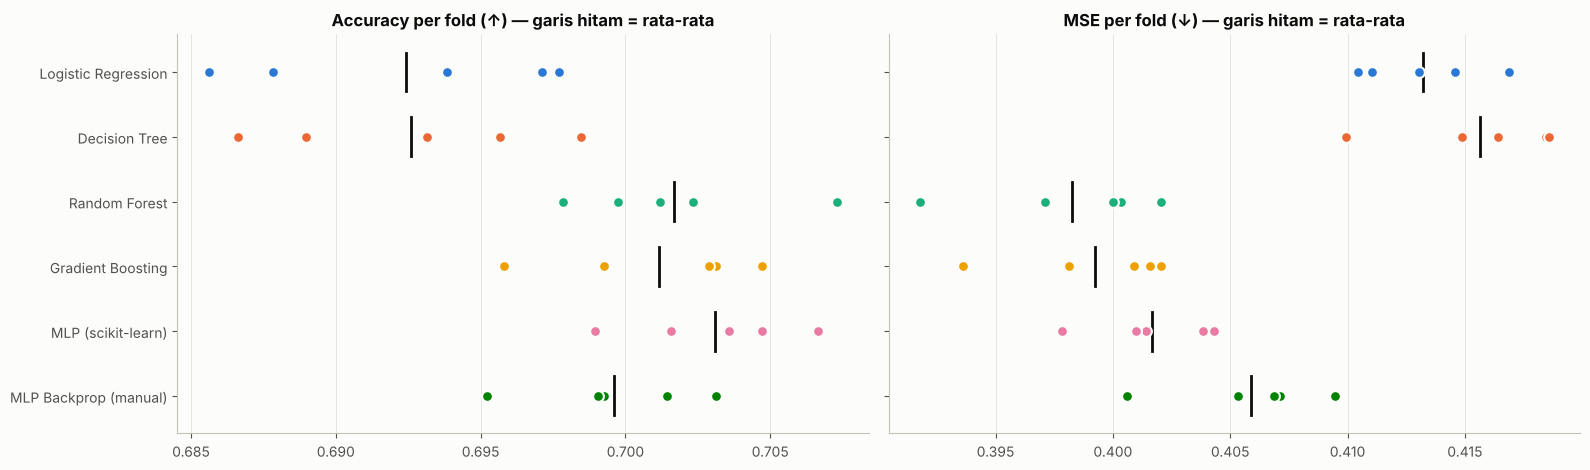

In [27]:
if RUN_CV:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
    for ax, col, title in [(axes[0], 'accuracy', 'Accuracy per fold (↑)'), (axes[1], 'mse', 'MSE per fold (↓)')]:
        for i, name in enumerate(MODEL_ORDER):
            v = cv.loc[cv.model == name, col]
            ax.scatter(v, np.full(len(v), i), color=MODEL_COLORS[name], s=60, edgecolor=SURFACE, linewidth=1.5, zorder=3)
            ax.plot([v.mean()] * 2, [i - 0.3, i + 0.3], color=INK, lw=2)
        ax.set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER if col == 'accuracy' else [''] * len(MODEL_ORDER))
        ax.invert_yaxis(); ax.set(title=title + ' — garis hitam = rata-rata'); ax.grid(axis='y', visible=False)
    plt.tight_layout(); savefig(fig, 'clf_cv_5fold.png'); plt.show()

## 12. Analisis Model Terbaik

### 12.1 Fitur paling berpengaruh (*permutation importance* pada data uji)

Selesai dalam 25 s


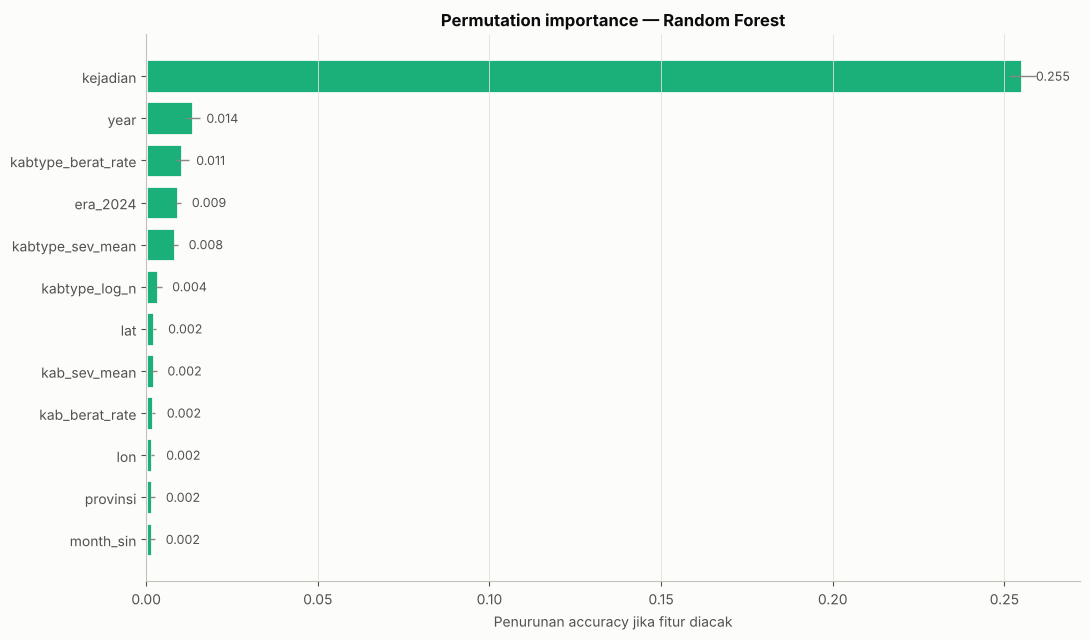

,penurunan_accuracy,std
kejadian,0.2552,0.0039
year,0.0135,0.0021
kabtype_berat_rate,0.0106,0.0019
era_2024,0.0093,0.0009
kabtype_sev_mean,0.0084,0.0010
kabtype_log_n,0.0036,0.0010
lat,0.0024,0.0004
kab_sev_mean,0.0022,0.0009
kab_berat_rate,0.0020,0.0004
lon,0.0018,0.0006


In [28]:
best_pipe = Pipeline([('pre', preprocessor), ('model', results[BEST]['model'])])
t0 = time.time()
pi = permutation_importance(best_pipe, X_test, y_test, scoring='accuracy', n_repeats=5,
                            random_state=RANDOM_SEED, n_jobs=1)
imp = (pd.DataFrame({'penurunan_accuracy': pi.importances_mean, 'std': pi.importances_std}, index=X_test.columns)
         .sort_values('penurunan_accuracy', ascending=False))
print(f'Selesai dalam {time.time() - t0:.0f} s')

fig, ax = plt.subplots(figsize=(11, 6.5))
top = imp.head(12)[::-1]
ax.barh(top.index, top.penurunan_accuracy, xerr=top['std'], color=MODEL_COLORS[BEST],
        edgecolor=SURFACE, linewidth=2, error_kw={'ecolor': MUTED, 'lw': 1})
for i, v in enumerate(top.penurunan_accuracy):
    ax.text(max(v, 0) + 0.004, i, f'{v:.3f}', va='center', fontsize=9, color=INK2)
ax.set(title=f'Permutation importance — {BEST}', xlabel='Penurunan accuracy jika fitur diacak')
ax.grid(axis='y', visible=False)
plt.tight_layout(); savefig(fig, 'clf_feature_importance.png'); plt.show()
display(imp.round(4))

### 12.2 Kinerja per jenis bencana dan per region

,n,accuracy,pct_berat_aktual,pct_berat_prediksi
kejadian,,,,
BANJIR,2830,0.538,49.187,66.078
CUACA EKSTREM,2437,0.675,2.995,0.000
TANAH LONGSOR,1594,0.770,3.074,0.125
KEBAKARAN HUTAN DAN LAHAN,1566,0.981,0.128,0.000
KEKERINGAN,176,0.847,85.227,99.432
GEMPABUMI,111,0.459,28.829,21.622
GELOMBANG PASANG DAN ABRASI,90,0.500,13.333,0.000
ERUPSI GUNUNG API,27,0.630,33.333,33.333
TSUNAMI,2,0.000,0.000,100.000


,n,accuracy
region,,
Kalimantan,971,0.823
Sumatera,2019,0.705
Jawa,4413,0.701
Bali,127,0.693
Sulawesi,742,0.613
Maluku,145,0.607
Papua,75,0.600
Nusa Tenggara,341,0.598


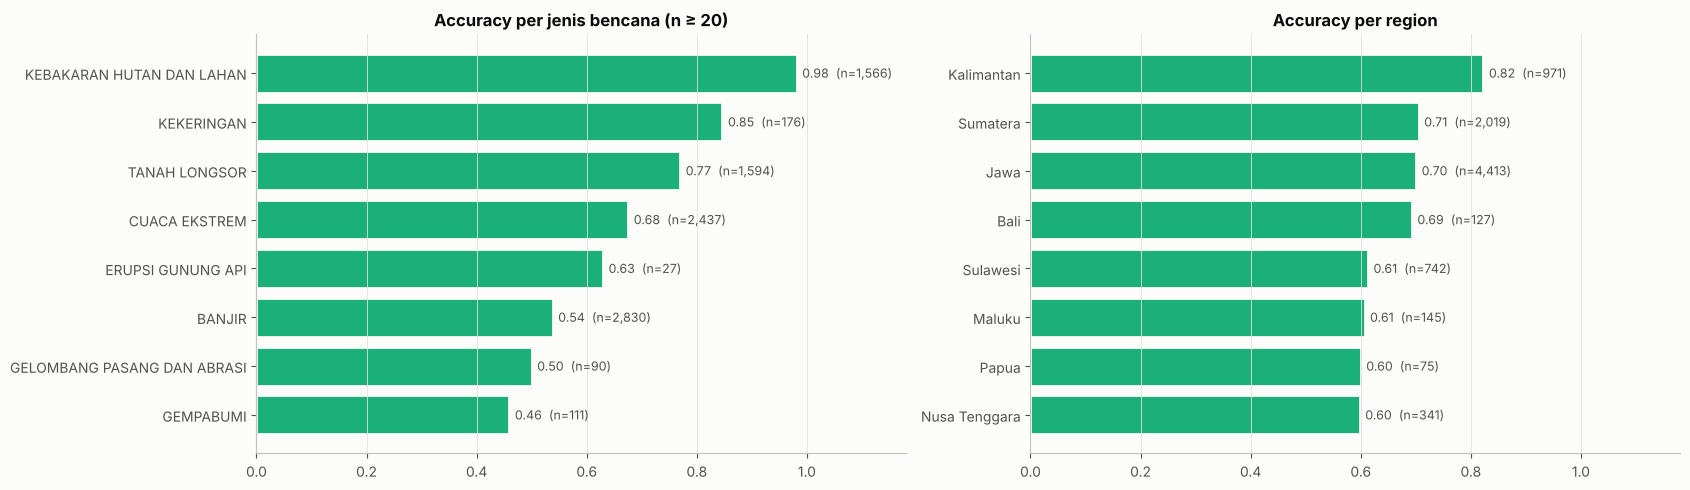

In [29]:
ev = X_test[['kejadian', 'region']].copy()
ev['aktual'], ev['prediksi'] = y_test, preds[BEST]
ev['benar'] = (ev.aktual == ev.prediksi).astype(int)

per_type = (ev.groupby('kejadian')
              .agg(n=('benar', 'size'), accuracy=('benar', 'mean'),
                   pct_berat_aktual=('aktual', lambda s: (s == 3).mean() * 100),
                   pct_berat_prediksi=('prediksi', lambda s: (s == 3).mean() * 100))
              .sort_values('n', ascending=False))
per_region = (ev.groupby('region').agg(n=('benar', 'size'), accuracy=('benar', 'mean'))
                .sort_values('accuracy', ascending=False))
display(per_type.round(3)); display(per_region.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
pt = per_type[per_type.n >= 20].sort_values('accuracy')
axes[0].barh(pt.index, pt.accuracy, color=MODEL_COLORS[BEST], edgecolor=SURFACE, linewidth=2)
for i, (a, n) in enumerate(zip(pt.accuracy, pt.n)):
    axes[0].text(a + 0.01, i, f'{a:.2f}  (n={n:,})', va='center', fontsize=9, color=INK2)
axes[0].set(title='Accuracy per jenis bencana (n ≥ 20)', xlim=(0, 1.18)); axes[0].grid(axis='y', visible=False)
pr = per_region.sort_values('accuracy')
axes[1].barh(pr.index, pr.accuracy, color=MODEL_COLORS[BEST], edgecolor=SURFACE, linewidth=2)
for i, (a, n) in enumerate(zip(pr.accuracy, pr.n)):
    axes[1].text(a + 0.01, i, f'{a:.2f}  (n={n:,})', va='center', fontsize=9, color=INK2)
axes[1].set(title='Accuracy per region', xlim=(0, 1.18)); axes[1].grid(axis='y', visible=False)
plt.tight_layout(); savefig(fig, 'clf_kinerja_per_segmen.png'); plt.show()

## 13. Uji *Out-of-Time* 2026 & Kaitan dengan Klaster Risiko

Simulasi pemakaian nyata: model terbaik dilatih ulang **hanya dengan data 2015–2025**, lalu diuji pada **laporan 2026** (periode yang sama
dengan analisis clustering rekan). Prediksi kemudian dihubungkan dengan label klaster K-Means (k = 4) per kab/kota dari
`bnpb_disaster_clusters.csv`. Label klaster **tidak** dipakai sebagai fitur (karena dibentuk dari dampak 2026), hanya sebagai lensa analisis.

In [30]:
mask_tr = (df.year <= 2025).values
mask_te = (df.year == 2026).values
pre_oot = make_preprocessor().fit(X[mask_tr])
m_oot = make_model(BEST).fit(pre_oot.transform(X[mask_tr]), y[mask_tr])
P_oot = m_oot.predict_proba(pre_oot.transform(X[mask_te]))
yp_oot, yt_oot = P_oot.argmax(1), y[mask_te]

oot = dict(accuracy=accuracy_score(yt_oot, yp_oot), balanced_accuracy=balanced_accuracy_score(yt_oot, yp_oot),
           f1_macro=f1_score(yt_oot, yp_oot, average='macro'), mse=mse_pdf(yt_oot, P_oot))
print(f'Out-of-time 2026 ({mask_te.sum():,} laporan) — model {BEST}')
print('  ' + ' | '.join(f'{k} = {v:.4f}' for k, v in oot.items()))
print(classification_report(yt_oot, yp_oot, target_names=SEV_LABELS, digits=4))

Out-of-time 2026 (2,285 laporan) — model Random Forest
  accuracy = 0.7982 | balanced_accuracy = 0.6375 | f1_macro = 0.6360 | mse = 0.2840
              precision    recall  f1-score   support

Tanpa Dampak     0.9745    0.9828    0.9786      1049
      Ringan     0.3922    0.1235    0.1878       162
      Sedang     0.6172    0.6703    0.6426       558
       Berat     0.7000    0.7733    0.7348       516

    accuracy                         0.7982      2285
   macro avg     0.6709    0.6375    0.6360      2285
weighted avg     0.7840    0.7982    0.7855      2285



Laporan 2026 yang cocok dengan klaster: 100.0%


,n_laporan,accuracy,pct_berat_aktual,pct_berat_prediksi,rata2_prob_berat
cluster_short,,,,,
Tingkat I - Rendah/Sporadis,573,0.873,0.000,6.108,0.082
Tingkat II - Kronis/Multi-Hazard,1318,0.794,21.472,23.065,0.191
Tingkat III - Kemanusiaan Akut,356,0.716,59.551,62.079,0.460
Tingkat IV - Katastropik Ekstrem,37,0.595,54.054,24.324,0.283


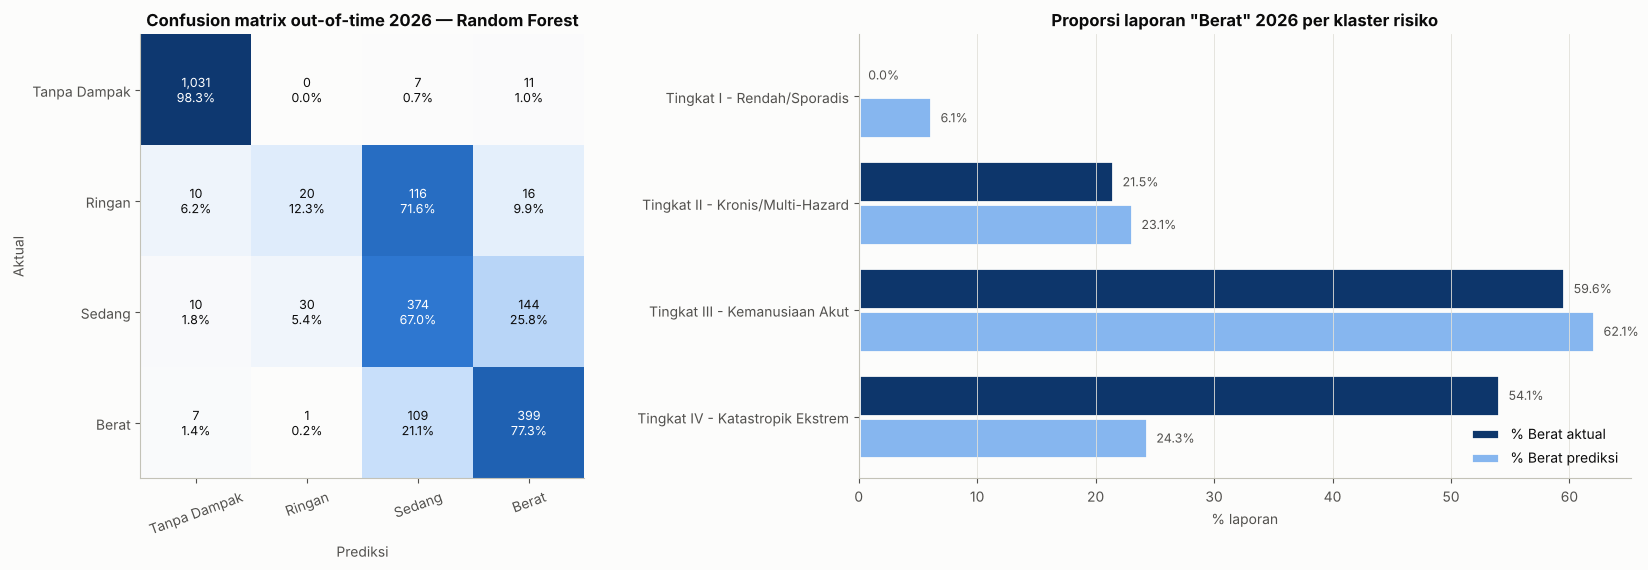

In [31]:
clusters = pd.read_csv(CLUSTER_FILE, usecols=['id_kab', 'cluster', 'cluster_short'])
d26 = df.loc[mask_te, ['id_kab', 'kabkot', 'kejadian']].copy()
d26['aktual'], d26['prediksi'], d26['p_berat'] = yt_oot, yp_oot, P_oot[:, 3]
d26['benar'] = (d26.aktual == d26.prediksi).astype(int)
d26 = d26.merge(clusters, on='id_kab', how='left')
print(f'Laporan 2026 yang cocok dengan klaster: {d26.cluster.notna().mean()*100:.1f}%')

per_cluster = (d26.dropna(subset=['cluster'])
                 .groupby(['cluster', 'cluster_short'])
                 .agg(n_laporan=('aktual', 'size'),
                      accuracy=('benar', 'mean'),
                      pct_berat_aktual=('aktual', lambda s: (s == 3).mean() * 100),
                      pct_berat_prediksi=('prediksi', lambda s: (s == 3).mean() * 100),
                      rata2_prob_berat=('p_berat', 'mean'))
                 .reset_index(level=0, drop=True))
display(per_cluster.round(3))

cm = confusion_matrix(yt_oot, yp_oot, labels=range(4)); cmn = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 5.8), gridspec_kw={'width_ratios': [1, 1.3]})
ax = axes[0]
ax.imshow(cmn, cmap=CM_CMAP, vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm[i, j]:,}\n{cmn[i, j]*100:.1f}%', ha='center', va='center', fontsize=9,
                color='#ffffff' if cmn[i, j] > 0.5 else INK)
ax.set_xticks(range(4), SEV_LABELS, rotation=20); ax.set_yticks(range(4), SEV_LABELS); ax.grid(False)
ax.set(xlabel='Prediksi', ylabel='Aktual', title=f'Confusion matrix out-of-time 2026 — {BEST}')

ax = axes[1]
yy = np.arange(len(per_cluster))
ax.barh(yy - 0.2, per_cluster.pct_berat_aktual, height=0.38, color=SEV_COLORS[3], edgecolor=SURFACE, linewidth=2, label='% Berat aktual')
ax.barh(yy + 0.2, per_cluster.pct_berat_prediksi, height=0.38, color=SEV_COLORS[0], edgecolor=SURFACE, linewidth=2, label='% Berat prediksi')
for i, (a, p) in enumerate(zip(per_cluster.pct_berat_aktual, per_cluster.pct_berat_prediksi)):
    ax.text(a + 0.8, i - 0.2, f'{a:.1f}%', va='center', fontsize=9, color=INK2)
    ax.text(p + 0.8, i + 0.2, f'{p:.1f}%', va='center', fontsize=9, color=INK2)
ax.set_yticks(yy, per_cluster.index); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set(title='Proporsi laporan "Berat" 2026 per klaster risiko', xlabel='% laporan')
ax.legend(loc='lower right')
plt.tight_layout(); savefig(fig, 'clf_out_of_time_2026_klaster.png'); plt.show()

## 14. Simpan Hasil

In [32]:
summary.to_csv(DATA_DIR / 'classification_metrics_comparison.csv', encoding='utf-8-sig')
pred_out = X_test[['kejadian', 'provinsi', 'region']].copy()
pred_out['severity_aktual'] = [SEV_LABELS[i] for i in y_test]
pred_out['severity_prediksi'] = [SEV_LABELS[i] for i in preds[BEST]]
for i, lab in enumerate(SEV_LABELS):
    pred_out[f'prob_{lab.lower().replace(" ", "_")}'] = probas[BEST][:, i].round(4)
pred_out.join(df[['date', 'kabkot']]).to_csv(DATA_DIR / 'classification_test_predictions.csv', encoding='utf-8-sig')
if RUN_CV:
    cv.to_csv(DATA_DIR / 'classification_cv_5fold.csv', index=False, encoding='utf-8-sig')
print('Tersimpan:')
for f in ['classification_metrics_comparison.csv', 'classification_test_predictions.csv', 'classification_cv_5fold.csv']:
    print('  data/processed/' + f)
for f in sorted(FIG_DIR.glob('clf_*.png')):
    print('  reports/figures/' + f.name)

Tersimpan:
  data/processed/classification_metrics_comparison.csv
  data/processed/classification_test_predictions.csv
  data/processed/classification_cv_5fold.csv
  reports/figures/clf_confusion_matrices.png
  reports/figures/clf_cv_5fold.png
  reports/figures/clf_distribusi_severity.png
  reports/figures/clf_feature_importance.png
  reports/figures/clf_gradient_descent_mse.png
  reports/figures/clf_kinerja_per_segmen.png
  reports/figures/clf_mse_validation_overlay.png
  reports/figures/clf_out_of_time_2026_klaster.png
  reports/figures/clf_perbandingan_model.png


## 15. Ringkasan Hasil & Insight

In [33]:
s = summary
lines = [f"- **Model terbaik**: {BEST} — accuracy {s.loc[BEST,'accuracy']:.4f}, balanced accuracy "
         f"{s.loc[BEST,'balanced_accuracy']:.4f}, F1-macro {s.loc[BEST,'f1_macro']:.4f}, MSE test {s.loc[BEST,'mse_test']:.4f}",
         f"- Rentang accuracy 6 model: {s.accuracy.min():.4f} – {s.accuracy.max():.4f}; rentang MSE test: "
         f"{s.mse_test.min():.4f} – {s.mse_test.max():.4f}",
         f"- Baseline kelas mayoritas: accuracy {base_major['accuracy']:.4f}; baseline jenis bencana saja: accuracy "
         f"{base_type['accuracy']:.4f}, MSE {base_type['mse_test']:.4f}",
         f"- Fitur terpenting: " + ', '.join(f"{i} ({v:.3f})" for i, v in imp.penurunan_accuracy.head(4).items()),
         f"- Out-of-time 2026: accuracy {oot['accuracy']:.4f}, balanced accuracy {oot['balanced_accuracy']:.4f}, MSE {oot['mse']:.4f}"]
display(Markdown('\n'.join(lines)))

- **Model terbaik**: Random Forest — accuracy 0.7013, balanced accuracy 0.6899, F1-macro 0.6897, MSE test 0.4018
- Rentang accuracy 6 model: 0.6865 – 0.7013; rentang MSE test: 0.4009 – 0.4213
- Baseline kelas mayoritas: accuracy 0.3473; baseline jenis bencana saja: accuracy 0.6647, MSE 0.4472
- Fitur terpenting: kejadian (0.255), year (0.014), kabtype_berat_rate (0.011), era_2024 (0.009)
- Out-of-time 2026: accuracy 0.7982, balanced accuracy 0.6375, MSE 0.2840

### Insight dari Pemodelan Klasifikasi

*(Angka berikut berasal dari eksekusi notebook ini dengan `RANDOM_SEED = 42`; dapat bergeser sedikit bila versi library berbeda.)*

#### 1. Model terbaik: Random Forest, tetapi selisih dengan model kuat lain tipis
| Model | Accuracy | Balanced acc. (CM) | MSE test | MSE CV 5-fold |
|---|---|---|---|---|
| **Random Forest** | **0.7013** | **0.6899** | 0.4018 | **0.3983 ± 0.004** |
| Gradient Boosting | 0.6982 | 0.6863 | **0.4009** | 0.3993 ± 0.004 |
| MLP Backprop (manual) | 0.6987 | 0.6871 | 0.4042 | 0.4059 ± 0.003 |
| MLP (scikit-learn) | 0.6983 | 0.6861 | 0.4024 | 0.4017 ± 0.003 |
| Decision Tree | 0.6879 | 0.6759 | 0.4213 | 0.4156 ± 0.004 |
| Logistic Regression | 0.6865 | 0.6720 | 0.4123 | 0.4132 ± 0.003 |

- Random Forest unggul di **accuracy** dan **balanced accuracy** pada data uji, berada di urutan ke-2 MSE test (hanya 0.0009 di atas Gradient Boosting),
  dan memiliki **MSE validasi silang terendah**. Model ini paling konsisten di ketiga kriteria.
- Empat model teratas hanya berselisih < 0.4 poin persen accuracy (masih dalam 1 standar deviasi CV). Artinya **batas kinerja ditentukan oleh informasi
  yang tersedia di fitur, bukan oleh pilihan algoritma**. Model linear (Logistic Regression) dan pohon tunggal tertinggal ±1.3 poin, tanda adanya
  interaksi non-linear antara jenis bencana × wilayah × era pelaporan.
- Semua model jauh di atas baseline: tebak kelas mayoritas (accuracy 0.347, MSE 1.305) dan model "jenis bencana saja" (accuracy 0.665, MSE 0.447).

#### 2. Apa yang diperlihatkan kurva Gradient Descent MSE
- **MLP Backprop manual** (rumus materi: sigmoid, $dC$, $dH$, $w = w + \mu \cdot I \cdot \delta$) menurunkan MSE dari ±1.01 (bobot acak) ke 0.397. Bentuk kurvanya
  sama dengan slide *Gradient Descent*: turun tajam di awal lalu melandai. Hasilnya setara dengan MLP scikit-learn, sehingga **implementasi teori sudah benar**.
- **MLP scikit-learn** mencapai MSE validation terendah di epoch 9, lalu MSE train terus turun sementara MSE validation naik. Ini contoh klasik **overfitting**,
  sehingga *early stopping* berdasarkan kurva validation sangat penting. Pola serupa terlihat pada Gradient Boosting (optimal di iterasi 64) dan Decision Tree (optimal di kedalaman 9).
- **Logistic Regression** konvergen hanya dalam 1–2 epoch (fungsi loss konveks, data besar), tetapi berhenti di MSE yang lebih tinggi karena hanya mampu memisahkan kelas secara linear.
- **Random Forest** memiliki MSE train 0.23 vs validation 0.40 (menghafal data latih), tetapi efek rata-rata ratusan pohon membuat MSE validation tidak naik dan melandai setelah ±100 pohon.

#### 3. Insight dari confusion matrix
- **Tanpa Dampak** diprediksi dengan presisi ±0.97 (didominasi Karhutla). **Ringan** (recall ±0.83) dan **Berat** (recall ±0.74; MLP manual 0.76) dikenali dengan baik.
- **Sedang adalah kelas tersulit** (recall hanya 0.32–0.39 di semua model) karena berada di tengah skala ordinal dan sering tertukar ke Ringan (±33%) atau Berat (±28%).
- Kesalahan hampir selalu ke **kelas tetangga**; kasus "Berat" yang diprediksi "Tanpa Dampak" hanya 0.3%. Untuk triase, model jarang meleset jauh.

#### 4. Faktor penentu keparahan (permutation importance)
- **Jenis bencana** adalah penentu utama (mengacak fitur ini menurunkan accuracy ±25 poin). Karhutla hampir selalu tanpa korban/kerusakan rumah tercatat,
  Kekeringan dan Banjir cenderung Berat (terdampak massal), sedangkan Tanah Longsor dan Cuaca Ekstrem cenderung Ringan/Sedang.
- **Riwayat keparahan jenis bencana yang sama di kab/kota yang sama** (`kabtype_berat_rate`, `kabtype_sev_mean`) adalah sinyal terpenting berikutnya:
  wilayah yang dulu sering mengalami banjir berat cenderung kembali mengalami banjir berat. Ini dasar kuantitatif untuk **mitigasi berbasis riwayat wilayah**.
- **Tahun/era pelaporan** juga penting (lihat poin 6). Musim (bulan, musim hujan) kecil pengaruhnya karena pola musiman sudah tercermin dalam jenis bencana
  (banjir/longsor di musim hujan, karhutla/kekeringan di kemarau).

#### 5. Di mana model kuat dan lemah
- **Per jenis**: Karhutla 0.98, Kekeringan 0.85, Tanah Longsor 0.77, Cuaca Ekstrem 0.68, sedangkan **Banjir hanya 0.54** dan **Gempabumi 0.46**.
  Keparahan banjir dan gempa sangat bergantung pada intensitas hazard (curah hujan, debit sungai, magnitudo, kedalaman), yang tidak ada di data BNPB ini.
- **Per region**: Kalimantan 0.82 (didominasi karhutla), Jawa/Sumatera ±0.70, sedangkan **Indonesia Timur** (Sulawesi, Maluku, Papua, Nusa Tenggara) hanya 0.60–0.61
  karena riwayat laporannya lebih sedikit sehingga fitur riwayat wilayah lebih lemah.

#### 6. Kualitas data: label dipengaruhi praktik pelaporan
- Mulai 2024 proporsi "Ringan" turun dari ±40% menjadi ±10% dan "Sedang" naik tajam (contoh: Tanah Longsor "Ringan" 77% pada 2023 menjadi 21% pada 2024),
  karena jumlah warga *menderita* mulai rutin dicatat. Severity BNPB mengukur **dampak yang tercatat**, tidak murni kekuatan bencana.
  Kelas "Tanpa Dampak" juga bisa berarti "dampak belum diisi".
- Fitur dampak di `bnpb_disaster_clf_ready.csv` membuat accuracy 99.8% karena **label leakage**. Untuk prediksi yang jujur, fitur tersebut harus dikeluarkan.

#### 7. Uji out-of-time 2026 & kaitan dengan klaster risiko rekan
- Dilatih hanya dengan data 2015–2025, Random Forest mencapai **accuracy 0.798 dan MSE 0.284** pada laporan 2026. Angka ini lebih tinggi karena 46% laporan 2026 adalah
  Karhutla yang mudah diprediksi. *Balanced accuracy* 0.638 lebih jujur: recall kelas Ringan hanya 0.12 (72% diprediksi Sedang) akibat pergeseran pola pelaporan sejak 2024.
- Dihubungkan dengan klaster K-Means rekan: proporsi prediksi "Berat" sangat sesuai untuk **Tingkat III – Kemanusiaan Akut** (prediksi 62.1% vs aktual 59.6%) dan
  **Tingkat II – Kronis/Multi-Hazard** (23.1% vs 21.5%). Namun untuk **Tingkat IV – Katastropik** model hanya memprediksi 24.3% Berat padahal aktualnya 54.1%.
  Kejadian ekstrem (erupsi Lewotobi, longsor fatal Bandung Barat, lahar dingin) **tidak dapat ditebak hanya dari jenis–lokasi–waktu**.
  Di sinilah klasifikasi dan clustering saling melengkapi.
  *(Catatan: klaster dibentuk dari dampak 2026, jadi ini pemeriksaan konsistensi, bukan validasi independen.)*

#### 8. Implikasi untuk DisasterWatch (SDGs 13 — Climate Action)
1. **Triase laporan awal**: probabilitas "Berat" dari model dapat dipakai BPBD/BNPB untuk memprioritaskan respons, terutama untuk banjir dan kekeringan
   yang paling sering berdampak massal.
2. **Aturan eskalasi tambahan**: untuk kab/kota di klaster Tingkat IV, laporan baru sebaiknya otomatis dinaikkan prioritasnya karena model cenderung meremehkan risiko ekstrem.
3. **Pengembangan berikutnya**: (a) tambah data intensitas hazard (curah hujan BMKG, magnitudo/kedalaman gempa, titik panas karhutla); (b) pendekatan ordinal atau
   *cost-sensitive* (mis. `class_weight`, penyesuaian ambang probabilitas) untuk menaikkan recall kelas Berat; (c) harmonisasi label lintas era pelaporan
   sebelum analisis tren jangka panjang.